# imports + config

In [8]:
from google.colab import drive
drive.mount('/content/drive')

ModuleNotFoundError: No module named 'google.colab'

In [ ]:
import json, warnings
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('inline')
import matplotlib.pyplot as plt
%matplotlib inline
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from pathlib import Path
from scipy import stats
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor
import shap
warnings.filterwarnings('ignore')

DEVICE       = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
MODEL_ROOT   = Path('/content/drive/MyDrive/uav_thesis/model_outputs/v2')
ENRICHED_DIR = MODEL_ROOT / 'v3b/07_enriched_parquets'
OUT_DIR      = MODEL_ROOT / 'v3b/08_anomaly_regression'
PLOT_DIR     = OUT_DIR / 'plots'
OUT_DIR.mkdir(parents=True, exist_ok=True)
PLOT_DIR.mkdir(parents=True, exist_ok=True)

FOLDS       = [f'fold_{i:02d}' for i in range(1, 6)]
TARGET      = 'target_energy_next_60s_wh'
OUTPUT_ROOT = Path('/content/drive/MyDrive/uav_thesis/processed_10hz/v2')

print(f'Device: {DEVICE}')
print(f'Enriched dir exists: {ENRICHED_DIR.exists()}')

Device: cuda
Enriched dir exists: True


# load enriched parquets

In [ ]:
enriched = {}
for fold in FOLDS:
    fold_dir = OUTPUT_ROOT / fold
    with open(fold_dir / f'feature_cols_{fold}.json') as f:
        feature_cols = json.load(f)
    enriched[fold] = {
        'feature_cols': feature_cols,
        'train': pd.read_parquet(ENRICHED_DIR / f'train_enriched_{fold}.parquet'),
        'val':   pd.read_parquet(ENRICHED_DIR / f'val_enriched_{fold}.parquet'),
        'test':  pd.read_parquet(ENRICHED_DIR / f'test_enriched_{fold}.parquet'),
    }
    tr = enriched[fold]['train']
    te = enriched[fold]['test']
    print(f'{fold} | train={len(tr)} val={len(enriched[fold]["val"])} '
          f'test={len(te)} | features={len(feature_cols)} | '
          f'anomaly_score nulls={te["anomaly_score"].isna().sum()}')

fold_01 | train=665216 val=110878 test=190831 | features=16 | anomaly_score nulls=0
fold_02 | train=643038 val=105335 test=218552 | features=16 | anomaly_score nulls=0
fold_03 | train=677953 val=105412 test=183560 | features=16 | anomaly_score nulls=0
fold_04 | train=671181 val=114458 test=181286 | features=16 | anomaly_score nulls=0
fold_05 | train=648120 val=126109 test=192696 | features=16 | anomaly_score nulls=0


# helper functions

In [ ]:
def get_Xy(df, feature_cols, use_anomaly):
    cols = feature_cols + (['anomaly_score'] if use_anomaly else [])
    return df[cols].values.astype(np.float32), df[TARGET].values.astype(np.float32)

def compute_metrics(y_true, y_pred, mean_power_w=None):
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2   = r2_score(y_true, y_pred)
    mask = y_true > 0.01
    mape = np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100
    rft  = (mae / mean_power_w * 3600) if mean_power_w else None
    return {'MAE': mae, 'RMSE': rmse, 'R2': r2, 'MAPE': mape, 'RFT_err_s': rft}

def wilcoxon_test(mae_baseline, mae_with):
    # one-sided: does +anomaly reduce MAE?
    diffs = np.array(mae_baseline) - np.array(mae_with)
    if np.all(diffs == 0):
        return np.nan, np.nan
    stat, p = stats.wilcoxon(diffs, alternative='greater')
    return stat, p

# tree baseline models (LR, RF, XGBoost)

In [ ]:
tree_results = []

for fold in FOLDS:
    fc   = enriched[fold]['feature_cols']
    df_tr = pd.concat([enriched[fold]['train'], enriched[fold]['val']], ignore_index=True)
    df_va = enriched[fold]['val']
    df_te = enriched[fold]['test']
    mean_pw = df_te['power_w'].mean() if 'power_w' in df_te.columns else None

    models_cfg = {
        'LinearRegression': LinearRegression(),
        'RandomForest': RandomForestRegressor(
            n_estimators=300, max_depth=15, min_samples_leaf=10,
            max_features=0.5, n_jobs=-1, random_state=42),
        'XGBoost': XGBRegressor(
            n_estimators=1000, max_depth=5, learning_rate=0.01,
            min_child_weight=10, subsample=0.8, colsample_bytree=0.8,
            early_stopping_rounds=50, random_state=42, verbosity=0, n_jobs=-1),
    }

    for model_name, mdl in models_cfg.items():
        for use_anomaly in [False, True]:
            X_tr, y_tr = get_Xy(df_tr, fc, use_anomaly)
            X_te, y_te = get_Xy(df_te, fc, use_anomaly)

            if model_name == 'XGBoost':
                X_va, y_va = get_Xy(df_va, fc, use_anomaly)
                mdl.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], verbose=False)
            else:
                mdl.fit(X_tr, y_tr)

            preds = mdl.predict(X_te)
            m = compute_metrics(y_te, preds, mean_pw)

            # subgroup MAE
            normal_mask   = df_te['dataset_label'] == 'normal'
            abnormal_mask = df_te['dataset_label'] == 'abnormal'
            m['MAE_normal']   = mean_absolute_error(y_te[normal_mask],   preds[normal_mask])   if normal_mask.any()   else np.nan
            m['MAE_abnormal'] = mean_absolute_error(y_te[abnormal_mask], preds[abnormal_mask]) if abnormal_mask.any() else np.nan

            m.update({'fold': fold, 'model': model_name,
                      'condition': 'with_anomaly' if use_anomaly else 'baseline'})
            tree_results.append(m)
            print(f'{fold} | {model_name:18s} | {"w/ anom" if use_anomaly else "baseline":10s} | '
                  f'MAE={m["MAE"]:.4f} RMSE={m["RMSE"]:.4f} R2={m["R2"]:.3f} '
                  f'MAPE={m["MAPE"]:.1f}% RFT={m["RFT_err_s"]:.1f}s')

df_tree = pd.DataFrame(tree_results)
df_tree.to_parquet(OUT_DIR / 'tree_model_results.parquet', index=False)

fold_01 | LinearRegression   | baseline   | MAE=0.4629 RMSE=0.7937 R2=0.851 MAPE=401.6% RFT=10050.3s
fold_01 | LinearRegression   | w/ anom    | MAE=0.4625 RMSE=0.7932 R2=0.851 MAPE=400.9% RFT=10042.7s
fold_01 | RandomForest       | baseline   | MAE=0.4138 RMSE=0.8825 R2=0.816 MAPE=137.7% RFT=8984.2s
fold_01 | RandomForest       | w/ anom    | MAE=0.5226 RMSE=1.0815 R2=0.723 MAPE=203.2% RFT=11346.7s
fold_01 | XGBoost            | baseline   | MAE=0.4074 RMSE=0.8833 R2=0.816 MAPE=152.0% RFT=8845.8s
fold_01 | XGBoost            | w/ anom    | MAE=0.4818 RMSE=0.9888 R2=0.769 MAPE=146.6% RFT=10462.6s
fold_02 | LinearRegression   | baseline   | MAE=0.7343 RMSE=1.8396 R2=0.896 MAPE=74.0% RFT=3021.1s
fold_02 | LinearRegression   | w/ anom    | MAE=0.7340 RMSE=1.8392 R2=0.896 MAPE=73.9% RFT=3019.6s
fold_02 | RandomForest       | baseline   | MAE=1.1876 RMSE=3.3739 R2=0.649 MAPE=149.4% RFT=4885.8s
fold_02 | RandomForest       | w/ anom    | MAE=1.2495 RMSE=3.2859 R2=0.667 MAPE=199.7% RFT=5140.5

# LSTM and BiLSTM architecture

In [ ]:
class LSTMRegressor(nn.Module):
    def __init__(self, n_features, hidden=128, layers=2, dropout=0.2, bidirectional=False):
        super().__init__()
        self.lstm = nn.LSTM(n_features, hidden, num_layers=layers,
                            dropout=dropout, batch_first=True,
                            bidirectional=bidirectional)
        fc_in = hidden * 2 if bidirectional else hidden
        self.fc = nn.Sequential(
            nn.Linear(fc_in, 64),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        out, _ = self.lstm(x)
        return self.fc(out[:, -1, :]).squeeze(-1)


def make_sequences(df, feature_cols, target, window=50, stride=10):
    X_list, y_list = [], []
    for _, grp in df.groupby('log_id', sort=False):
        vals = grp[feature_cols].values.astype(np.float32)
        tgt  = grp[target].values.astype(np.float32)
        for i in range(0, len(vals) - window + 1, stride):
            X_list.append(vals[i:i+window])
            y_list.append(tgt[i + window - 1])
    return np.array(X_list), np.array(y_list)


def train_lstm(model, X_tr, y_tr, X_va, y_va,
               lr=1e-3, epochs=100, patience=10, batch=256):
    opt      = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn  = nn.MSELoss()
    tr_ds    = TensorDataset(torch.tensor(X_tr), torch.tensor(y_tr))
    tr_dl    = DataLoader(tr_ds, batch_size=batch, shuffle=True)
    X_va_t   = torch.tensor(X_va).to(DEVICE)
    y_va_t   = torch.tensor(y_va).to(DEVICE)

    best_val, patience_ctr, best_state = np.inf, 0, None
    for epoch in range(epochs):
        model.train()
        for xb, yb in tr_dl:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            opt.zero_grad()
            loss_fn(model(xb), yb).backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
        model.eval()
        with torch.no_grad():
            val_loss = loss_fn(model(X_va_t), y_va_t).item()
        if val_loss < best_val:
            best_val    = val_loss
            best_state  = {k: v.cpu().clone() for k, v in model.state_dict().items()}
            patience_ctr = 0
        else:
            patience_ctr += 1
            if patience_ctr >= patience:
                break
    model.load_state_dict(best_state)
    return model


def predict_lstm(model, X, batch=512):
    model.eval()
    preds = []
    with torch.no_grad():
        for i in range(0, len(X), batch):
            xb = torch.tensor(X[i:i+batch]).to(DEVICE)
            preds.append(model(xb).cpu().numpy())
    return np.concatenate(preds)

# run LSTM and BiLSTM

In [ ]:
WINDOW, STRIDE = 50, 10
seq_results = []

for fold in FOLDS:
    fc      = enriched[fold]['feature_cols']
    df_tr   = enriched[fold]['train']
    df_va   = enriched[fold]['val']
    df_te   = enriched[fold]['test']
    mean_pw = df_te['power_w'].mean() if 'power_w' in df_te.columns else None

    for use_anomaly in [False, True]:
        cols   = fc + (['anomaly_score'] if use_anomaly else [])
        n_feat = len(cols)

        X_tr, y_tr = make_sequences(df_tr, cols, TARGET, WINDOW, STRIDE)
        X_va, y_va = make_sequences(df_va, cols, TARGET, WINDOW, STRIDE)
        X_te, y_te = make_sequences(df_te, cols, TARGET, WINDOW, STRIDE)

        # rebuild label masks aligned to sequence windows
        te_idx = []
        for _, grp in df_te.groupby('log_id', sort=False):
            n = len(grp)
            for i in range(0, n - WINDOW + 1, STRIDE):
                te_idx.append(grp.index[i + WINDOW - 1])
        te_labels = df_te.loc[te_idx, 'dataset_label'].values
        norm_seq  = te_labels == 'normal'
        abn_seq   = te_labels == 'abnormal'

        for arch, bidir in [('LSTM', False), ('BiLSTM', True)]:

            # ── checkpoint skip ──
            ckpt = OUT_DIR / f'{arch.lower()}_{fold}_{"anom" if use_anomaly else "base"}.pt'
            if ckpt.exists():
                print(f'  Skipping {arch} {fold} {"anom" if use_anomaly else "base"} — checkpoint exists')
                continue

            print(f'{fold} | {arch} | {"w/ anom" if use_anomaly else "baseline"} ...', end=' ')
            model = LSTMRegressor(n_feat, hidden=128, layers=2,
                                  dropout=0.2, bidirectional=bidir).to(DEVICE)
            model = train_lstm(model, X_tr, y_tr, X_va, y_va,
                               lr=1e-3, epochs=100, patience=10, batch=256)
            preds = predict_lstm(model, X_te)
            m = compute_metrics(y_te, preds, mean_pw)
            m['MAE_normal']   = mean_absolute_error(y_te[norm_seq], preds[norm_seq]) if norm_seq.any() else np.nan
            m['MAE_abnormal'] = mean_absolute_error(y_te[abn_seq],  preds[abn_seq])  if abn_seq.any()  else np.nan
            m.update({'fold': fold, 'model': arch,
                      'condition': 'with_anomaly' if use_anomaly else 'baseline'})
            seq_results.append(m)

            # save weights + partial results
            torch.save(model.state_dict(), ckpt)
            pd.DataFrame(seq_results).to_parquet(OUT_DIR / 'seq_results_partial.parquet', index=False)
            print(f'MAE={m["MAE"]:.4f} RMSE={m["RMSE"]:.4f} R2={m["R2"]:.3f}')

df_seq = pd.DataFrame(seq_results)
df_seq.to_parquet(OUT_DIR / 'seq_model_results.parquet', index=False)

  Skipping LSTM fold_01 base — checkpoint exists
  Skipping BiLSTM fold_01 base — checkpoint exists
  Skipping LSTM fold_01 anom — checkpoint exists
  Skipping BiLSTM fold_01 anom — checkpoint exists
  Skipping LSTM fold_02 base — checkpoint exists
  Skipping BiLSTM fold_02 base — checkpoint exists
  Skipping LSTM fold_02 anom — checkpoint exists
  Skipping BiLSTM fold_02 anom — checkpoint exists
  Skipping LSTM fold_03 base — checkpoint exists
  Skipping BiLSTM fold_03 base — checkpoint exists
  Skipping LSTM fold_03 anom — checkpoint exists
  Skipping BiLSTM fold_03 anom — checkpoint exists
  Skipping LSTM fold_04 base — checkpoint exists
  Skipping BiLSTM fold_04 base — checkpoint exists
  Skipping LSTM fold_04 anom — checkpoint exists
  Skipping BiLSTM fold_04 anom — checkpoint exists
  Skipping LSTM fold_05 base — checkpoint exists
  Skipping BiLSTM fold_05 base — checkpoint exists
  Skipping LSTM fold_05 anom — checkpoint exists
  Skipping BiLSTM fold_05 anom — checkpoint exists


# combine results + Wilcoxon test

In [ ]:
WINDOW, STRIDE = 50, 10
seq_results = []

for fold in FOLDS:
    fc      = enriched[fold]['feature_cols']
    fc_clean = [c for c in fc if c != 'anomaly_flag']
    df_tr   = enriched[fold]['train']
    df_va   = enriched[fold]['val']
    df_te   = enriched[fold]['test']
    mean_pw = df_te['power_w'].mean() if 'power_w' in df_te.columns else None

    for use_anomaly in [False, True]:
        cols   = fc_clean + (['anomaly_score'] if use_anomaly else [])
        n_feat = len(cols)

        X_te, y_te = make_sequences(df_te, cols, TARGET, WINDOW, STRIDE)

        # rebuild label masks
        te_idx = []
        for _, grp in df_te.groupby('log_id', sort=False):
            n = len(grp)
            for i in range(0, n - WINDOW + 1, STRIDE):
                te_idx.append(grp.index[i + WINDOW - 1])
        te_labels = df_te.loc[te_idx, 'dataset_label'].values
        norm_seq  = te_labels == 'normal'
        abn_seq   = te_labels == 'abnormal'

        for arch, bidir in [('LSTM', False), ('BiLSTM', True)]:
            cond_str = 'anom' if use_anomaly else 'base'
            ckpt = OUT_DIR / f'{arch.lower()}_{fold}_{cond_str}.pt'

            model = LSTMRegressor(n_feat, hidden=128, layers=2,
                                  dropout=0.2, bidirectional=bidir).to(DEVICE)
            model.load_state_dict(torch.load(ckpt, map_location=DEVICE))
            model.eval()

            preds = predict_lstm(model, X_te)
            m = compute_metrics(y_te, preds, mean_pw)
            m['MAE_normal']   = mean_absolute_error(y_te[norm_seq], preds[norm_seq]) if norm_seq.any() else np.nan
            m['MAE_abnormal'] = mean_absolute_error(y_te[abn_seq],  preds[abn_seq])  if abn_seq.any()  else np.nan
            m.update({'fold': fold, 'model': arch,
                      'condition': 'with_anomaly' if use_anomaly else 'baseline'})
            seq_results.append(m)
            print(f'{fold} | {arch:6s} | {"w/anom" if use_anomaly else "base  "} | '
                  f'MAE={m["MAE"]:.4f} RMSE={m["RMSE"]:.4f} R2={m["R2"]:.3f}')

df_seq = pd.DataFrame(seq_results)
df_seq.to_parquet(OUT_DIR / 'seq_model_results.parquet', index=False)
print(f'\nSaved {len(df_seq)} rows to seq_model_results.parquet')

fold_01 | LSTM   | base   | MAE=0.3665 RMSE=0.8315 R2=0.837
fold_01 | BiLSTM | base   | MAE=0.4112 RMSE=0.9720 R2=0.777
fold_01 | LSTM   | w/anom | MAE=0.3421 RMSE=0.8117 R2=0.844
fold_01 | BiLSTM | w/anom | MAE=0.5289 RMSE=1.1341 R2=0.696
fold_02 | LSTM   | base   | MAE=0.9596 RMSE=2.5910 R2=0.794
fold_02 | BiLSTM | base   | MAE=1.1416 RMSE=2.8181 R2=0.756
fold_02 | LSTM   | w/anom | MAE=0.9273 RMSE=2.3675 R2=0.828
fold_02 | BiLSTM | w/anom | MAE=0.9718 RMSE=2.7567 R2=0.767
fold_03 | LSTM   | base   | MAE=0.4465 RMSE=1.0838 R2=0.911
fold_03 | BiLSTM | base   | MAE=0.4769 RMSE=0.9829 R2=0.927
fold_03 | LSTM   | w/anom | MAE=0.6084 RMSE=1.4810 R2=0.834
fold_03 | BiLSTM | w/anom | MAE=0.4270 RMSE=0.9326 R2=0.934
fold_04 | LSTM   | base   | MAE=0.2372 RMSE=0.3794 R2=0.897
fold_04 | BiLSTM | base   | MAE=0.3723 RMSE=0.7141 R2=0.636
fold_04 | LSTM   | w/anom | MAE=0.2100 RMSE=0.3610 R2=0.907
fold_04 | BiLSTM | w/anom | MAE=0.2968 RMSE=0.5091 R2=0.815
fold_05 | LSTM   | base   | MAE=0.5917 R

In [ ]:
df_tree = pd.read_parquet(OUT_DIR / 'tree_model_results.parquet')
df_seq  = pd.read_parquet(OUT_DIR / 'seq_model_results.parquet')
df_all  = pd.concat([df_tree, df_seq], ignore_index=True)

print(f'Total rows: {len(df_all)}')
print(df_all.groupby(['model','condition']).size().unstack())

# rebuild summary
summary_rows = []
for model in ['LinearRegression', 'RandomForest', 'XGBoost', 'LSTM', 'BiLSTM']:
    for cond in ['baseline', 'with_anomaly']:
        sub = df_all[(df_all['model']==model)&(df_all['condition']==cond)]
        if sub.empty:
            continue
        row = {'model': model, 'condition': cond}
        for col in ['MAE','RMSE','R2','MAPE','RFT_err_s','MAE_normal','MAE_abnormal']:
            row[f'{col}_mean'] = sub[col].mean()
            row[f'{col}_std']  = sub[col].std()
        summary_rows.append(row)
df_summary = pd.DataFrame(summary_rows)

print('\n=== Mean ± std across 5 folds ===')
print(df_summary[['model','condition','MAE_mean','MAE_std',
                   'R2_mean','MAE_normal_mean','MAE_abnormal_mean']].to_string(index=False))

# Wilcoxon
print('\n=== Wilcoxon signed-rank (does +anomaly reduce MAE?) ===')
wilcoxon_rows = []
for model in ['LinearRegression', 'RandomForest', 'XGBoost', 'LSTM', 'BiLSTM']:
    base  = df_all[(df_all['model']==model)&(df_all['condition']=='baseline')]\
            .sort_values('fold')['MAE'].values
    with_ = df_all[(df_all['model']==model)&(df_all['condition']=='with_anomaly')]\
            .sort_values('fold')['MAE'].values
    if len(base) < 2 or len(with_) < 2:
        continue
    diffs = base - with_
    if np.all(diffs == 0):
        stat, p = np.nan, np.nan
    else:
        stat, p = stats.wilcoxon(diffs, alternative='greater')
    delta = base.mean() - with_.mean()
    sig   = p < 0.05 if not np.isnan(p) else False
    wilcoxon_rows.append({
        'model': model, 'MAE_base': round(base.mean(),4),
        'MAE_with': round(with_.mean(),4), 'delta_MAE': round(delta,4),
        'W_stat': stat, 'p_value': round(p,4) if not np.isnan(p) else np.nan,
        'significant': sig
    })
    print(f'{model:18s} | base={base.mean():.4f} with={with_.mean():.4f} '
          f'delta={delta:+.4f} | p={p:.4f} {"✓ significant" if sig else "✗"}')

df_wilcoxon = pd.DataFrame(wilcoxon_rows)
df_summary.to_csv(OUT_DIR / 'summary_all_models.csv', index=False)
df_wilcoxon.to_csv(OUT_DIR / 'wilcoxon_results.csv', index=False)
df_all.to_parquet(OUT_DIR / 'all_results.parquet', index=False)
print('\nAll saved.')

Total rows: 50
condition         baseline  with_anomaly
model                                   
BiLSTM                   5             5
LSTM                     5             5
LinearRegression         5             5
RandomForest             5             5
XGBoost                  5             5

=== Mean ± std across 5 folds ===
           model    condition  MAE_mean  MAE_std  R2_mean  MAE_normal_mean  MAE_abnormal_mean
LinearRegression     baseline  0.563395 0.172175 0.818346         0.370615           1.013165
LinearRegression with_anomaly  0.563090 0.172137 0.818483         0.370343           1.012781
    RandomForest     baseline  0.815200 0.283038 0.125771         0.421832           1.741933
    RandomForest with_anomaly  0.892104 0.268604 0.130528         0.473856           1.882833
         XGBoost     baseline  0.722425 0.303240 0.533269         0.320321           1.684344
         XGBoost with_anomaly  0.774668 0.263807 0.483419         0.405067           1.660780
     

# plots

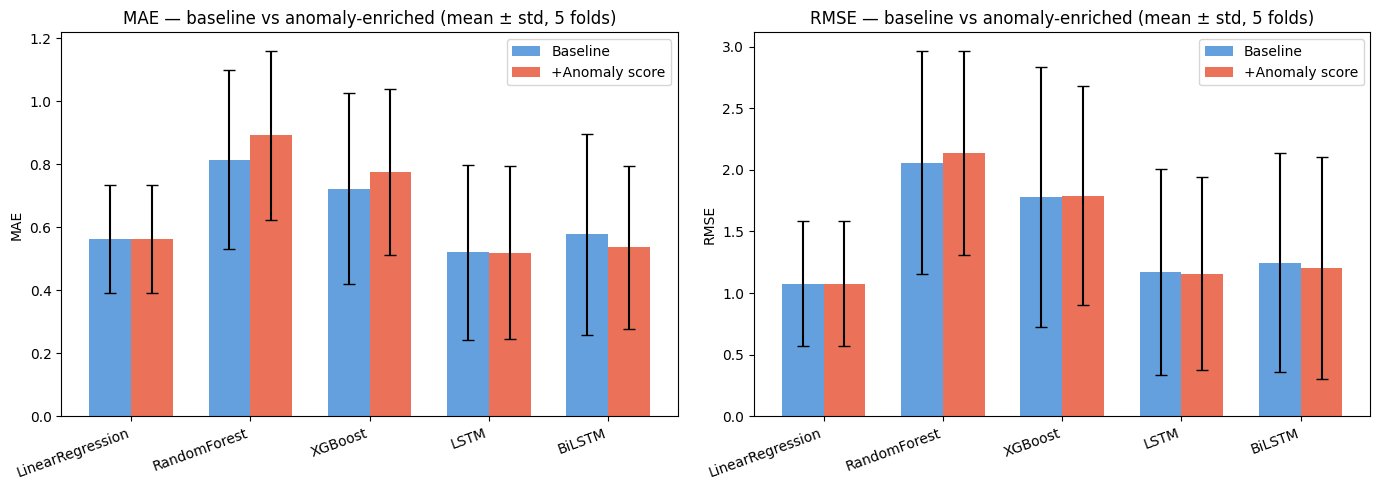

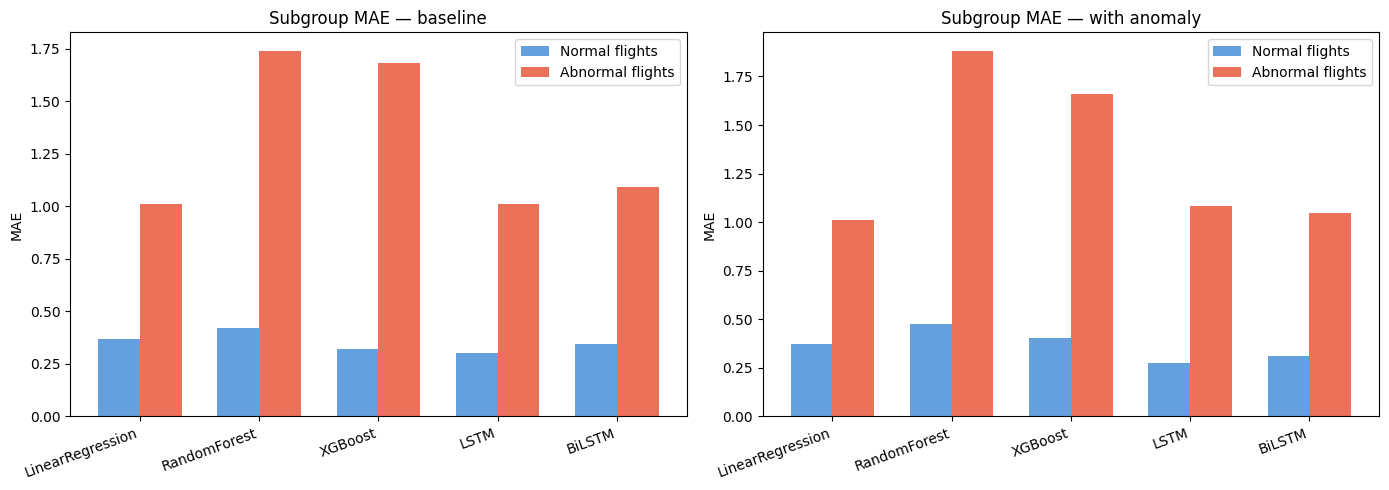

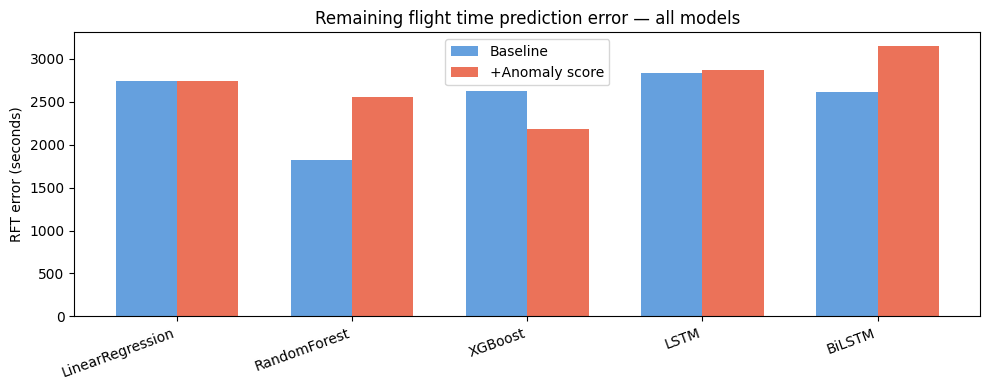

In [ ]:
MODELS = ['LinearRegression', 'RandomForest', 'XGBoost', 'LSTM', 'BiLSTM']
COLORS = {'baseline': '#4A90D9', 'with_anomaly': '#E8593C'}

# ── Plot 1: MAE with vs without, per model ────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, metric in zip(axes, ['MAE', 'RMSE']):
    x = np.arange(len(MODELS))
    w = 0.35
    for i, cond in enumerate(['baseline', 'with_anomaly']):
        means = [df_summary.loc[(df_summary['model']==m)&(df_summary['condition']==cond),
                                f'{metric}_mean'].values[0]
                 if len(df_summary.loc[(df_summary['model']==m)&(df_summary['condition']==cond)]) > 0
                 else np.nan for m in MODELS]
        stds  = [df_summary.loc[(df_summary['model']==m)&(df_summary['condition']==cond),
                                f'{metric}_std'].values[0]
                 if len(df_summary.loc[(df_summary['model']==m)&(df_summary['condition']==cond)]) > 0
                 else np.nan for m in MODELS]
        ax.bar(x + (i-0.5)*w, means, w, yerr=stds, capsize=4,
               color=COLORS[cond], alpha=0.85,
               label='Baseline' if cond == 'baseline' else '+Anomaly score')
    ax.set_xticks(x)
    ax.set_xticklabels(MODELS, rotation=20, ha='right')
    ax.set_ylabel(metric)
    ax.set_title(f'{metric} — baseline vs anomaly-enriched ($\\mu \\pm \\sigma$, 5 folds)')
    ax.legend()
plt.tight_layout()
plt.savefig(PLOT_DIR / 'mae_rmse_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

# ── Plot 2: Normal vs Abnormal MAE subgroup ───────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, cond in zip(axes, ['baseline', 'with_anomaly']):
    sub = df_summary[df_summary['condition'] == cond]
    x   = np.arange(len(MODELS))
    w   = 0.35
    norm_means = [sub.loc[sub['model']==m, 'MAE_normal_mean'].values[0]
                  if len(sub.loc[sub['model']==m]) > 0 else np.nan for m in MODELS]
    abn_means  = [sub.loc[sub['model']==m, 'MAE_abnormal_mean'].values[0]
                  if len(sub.loc[sub['model']==m]) > 0 else np.nan for m in MODELS]
    ax.bar(x - w/2, norm_means, w, color='#4A90D9', alpha=0.85, label='Normal flights')
    ax.bar(x + w/2, abn_means,  w, color='#E8593C', alpha=0.85, label='Abnormal flights')
    ax.set_xticks(x)
    ax.set_xticklabels(MODELS, rotation=20, ha='right')
    ax.set_ylabel('MAE')
    ax.set_title(f'Subgroup MAE — {cond.replace("_"," ")}')
    ax.legend()
plt.tight_layout()
plt.savefig(PLOT_DIR / 'subgroup_mae_normal_vs_abnormal.png', dpi=150, bbox_inches='tight')
plt.show()

# ── Plot 3: RFT error per model ───────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(MODELS))
w = 0.35
for i, cond in enumerate(['baseline', 'with_anomaly']):
    rft = [df_summary.loc[(df_summary['model']==m)&(df_summary['condition']==cond),
                           'RFT_err_s_mean'].values[0]
           if len(df_summary.loc[(df_summary['model']==m)&(df_summary['condition']==cond)]) > 0
           else np.nan for m in MODELS]
    ax.bar(x + (i-0.5)*w, rft, w,
           color=COLORS[cond], alpha=0.85,
           label='Baseline' if cond == 'baseline' else '+Anomaly score')
ax.set_xticks(x)
ax.set_xticklabels(MODELS, rotation=20, ha='right')
ax.set_ylabel('RFT error (seconds)')
ax.set_title('Remaining flight time prediction error — all models')
ax.legend()
plt.tight_layout()
plt.savefig(PLOT_DIR / 'rft_error_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

OUT_DIR  = Path(" MODEL_ROOT / 'v3b/08_anomaly_regression'")   # same as in your notebook
PLOT_DIR = Path("OUT_DIR / 'plots'")

df_summary = pd.read_csv(OUT_DIR / 'summary_all_models.csv')
MODELS = ['LinearRegression', 'RandomForest', 'XGBoost', 'LSTM', 'BiLSTM']
COLORS = {'baseline': '#4A90D9', 'with_anomaly': '#E8593C'}

# ── Plot 1: MAE with vs without, per model ────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, metric in zip(axes, ['MAE', 'RMSE']):
    x = np.arange(len(MODELS))
    w = 0.35
    for i, cond in enumerate(['baseline', 'with_anomaly']):
        means = [df_summary.loc[(df_summary['model']==m)&(df_summary['condition']==cond),
                                f'{metric}_mean'].values[0]
                 if len(df_summary.loc[(df_summary['model']==m)&(df_summary['condition']==cond)]) > 0
                 else np.nan for m in MODELS]
        stds  = [df_summary.loc[(df_summary['model']==m)&(df_summary['condition']==cond),
                                f'{metric}_std'].values[0]
                 if len(df_summary.loc[(df_summary['model']==m)&(df_summary['condition']==cond)]) > 0
                 else np.nan for m in MODELS]
        ax.bar(x + (i-0.5)*w, means, w, yerr=stds, capsize=4,
               color=COLORS[cond], alpha=0.85,
               label='Baseline' if cond == 'baseline' else '+Anomaly score')
    ax.set_xticks(x)
    ax.set_xticklabels(MODELS, rotation=20, ha='right')
    ax.set_ylabel(metric)
    ax.set_title(f'{metric} — baseline vs anomaly-enriched ($\\mu \\pm \\sigma$, 5 folds)')
    ax.legend()
plt.tight_layout()
plt.savefig(PLOT_DIR / 'mae_rmse_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

# ── Plot 2: Normal vs Abnormal MAE subgroup ───────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, cond in zip(axes, ['baseline', 'with_anomaly']):
    sub = df_summary[df_summary['condition'] == cond]
    x   = np.arange(len(MODELS))
    w   = 0.35
    norm_means = [sub.loc[sub['model']==m, 'MAE_normal_mean'].values[0]
                  if len(sub.loc[sub['model']==m]) > 0 else np.nan for m in MODELS]
    abn_means  = [sub.loc[sub['model']==m, 'MAE_abnormal_mean'].values[0]
                  if len(sub.loc[sub['model']==m]) > 0 else np.nan for m in MODELS]
    ax.bar(x - w/2, norm_means, w, color='#4A90D9', alpha=0.85, label='Normal flights')
    ax.bar(x + w/2, abn_means,  w, color='#E8593C', alpha=0.85, label='Abnormal flights')
    ax.set_xticks(x)
    ax.set_xticklabels(MODELS, rotation=20, ha='right')
    ax.set_ylabel('MAE')
    ax.set_title(f'Subgroup MAE — {cond.replace("_"," ")}')
    ax.legend()
plt.tight_layout()
plt.savefig(PLOT_DIR / 'subgroup_mae_normal_vs_abnormal.png', dpi=150, bbox_inches='tight')
plt.show()

# ── Plot 3: RFT error per model ───────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(MODELS))
w = 0.35
for i, cond in enumerate(['baseline', 'with_anomaly']):
    rft = [df_summary.loc[(df_summary['model']==m)&(df_summary['condition']==cond),
                           'RFT_err_s_mean'].values[0]
           if len(df_summary.loc[(df_summary['model']==m)&(df_summary['condition']==cond)]) > 0
           else np.nan for m in MODELS]
    ax.bar(x + (i-0.5)*w, rft, w,
           color=COLORS[cond], alpha=0.85,
           label='Baseline' if cond == 'baseline' else '+Anomaly score')
ax.set_xticks(x)
ax.set_xticklabels(MODELS, rotation=20, ha='right')
ax.set_ylabel('RFT error (seconds)')
ax.set_title('Remaining flight time prediction error — all models')
ax.legend()
plt.tight_layout()
plt.savefig(PLOT_DIR / 'rft_error_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

FileNotFoundError: [Errno 2] No such file or directory: " MODEL_ROOT / 'v3b/08_anomaly_regression'/summary_all_models.csv"

# SHAP for best tree model

In [ ]:
print(X_tr.shape)
print(X_te.shape)

(64311, 50, 17)
(19123, 50, 17)


X_tr shape: (776094, 17)  cols: 17
shap_vals shape: (2000, 17)
cols length    : 17
anomaly_score SHAP rank: 3 of 17


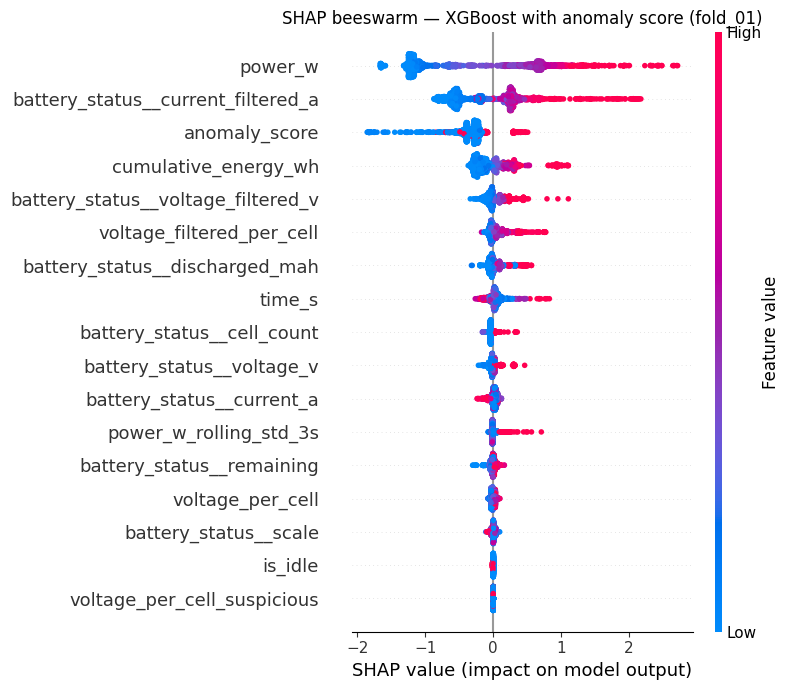

anomaly_score mean |SHAP| — normal  : 0.35402
anomaly_score mean |SHAP| — abnormal: 0.36346


In [ ]:
BEST_TREE = 'XGBoost'

fold  = 'fold_01'
fc    = enriched[fold]['feature_cols']
cols  = [c for c in fc if c != 'anomaly_flag'] + ['anomaly_score']  # exclude anomaly_flag
df_tr = pd.concat([enriched[fold]['train'], enriched[fold]['val']], ignore_index=True)
df_va = enriched[fold]['val']
df_te = enriched[fold]['test']

X_tr = df_tr[cols].values.astype(np.float32); y_tr = df_tr[TARGET].values.astype(np.float32)
X_va = df_va[cols].values.astype(np.float32); y_va = df_va[TARGET].values.astype(np.float32)
X_te = df_te[cols].values.astype(np.float32); y_te = df_te[TARGET].values.astype(np.float32)

print(f'X_tr shape: {X_tr.shape}  cols: {len(cols)}')

if BEST_TREE == 'XGBoost':
    mdl = XGBRegressor(n_estimators=1000, max_depth=5, learning_rate=0.01,
                       min_child_weight=10, subsample=0.8, colsample_bytree=0.8,
                       early_stopping_rounds=50, random_state=42, verbosity=0, n_jobs=-1)
    mdl.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], verbose=False)
    explainer = shap.TreeExplainer(mdl)
else:
    mdl = RandomForestRegressor(n_estimators=300, max_depth=15, min_samples_leaf=10,
                                max_features=0.5, n_jobs=-1, random_state=42)
    mdl.fit(X_tr, y_tr)
    explainer = shap.TreeExplainer(mdl)

# sample 2000 rows
idx       = np.random.choice(len(X_te), min(2000, len(X_te)), replace=False)
shap_vals = explainer.shap_values(X_te[idx])

print(f'shap_vals shape: {shap_vals.shape}')
print(f'cols length    : {len(cols)}')
assert shap_vals.shape[1] == len(cols), f'Mismatch: {shap_vals.shape[1]} vs {len(cols)}'

# beeswarm
shap.summary_plot(shap_vals, X_te[idx], feature_names=cols,
                  show=False, plot_size=(8, 7))
anom_idx  = cols.index('anomaly_score')
rank      = np.argsort(np.abs(shap_vals).mean(0))[::-1].tolist().index(anom_idx) + 1
print(f'anomaly_score SHAP rank: {rank} of {len(cols)}')
plt.title(f'SHAP beeswarm — {BEST_TREE} with anomaly score (fold_01)')
plt.tight_layout()
plt.savefig(PLOT_DIR / 'shap_beeswarm.png', dpi=150, bbox_inches='tight')
plt.show()

# normal vs abnormal SHAP for anomaly_score
normal_idx   = np.where(df_te['dataset_label'].values[idx] == 'normal')[0]
abnormal_idx = np.where(df_te['dataset_label'].values[idx] == 'abnormal')[0]
print(f'anomaly_score mean |SHAP| — normal  : {np.abs(shap_vals[normal_idx, anom_idx]).mean():.5f}')
print(f'anomaly_score mean |SHAP| — abnormal: {np.abs(shap_vals[abnormal_idx, anom_idx]).mean():.5f}')

# per-flight timeline plot

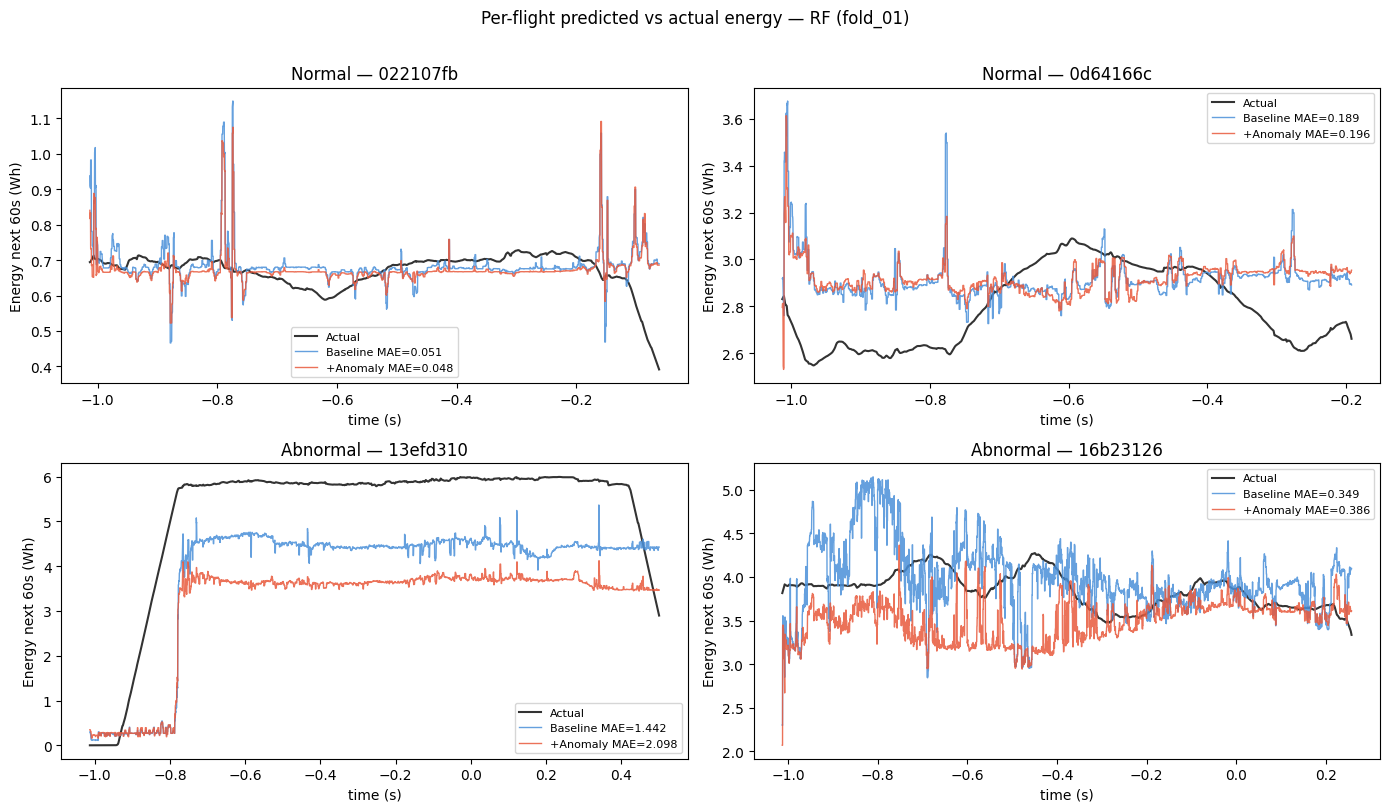

In [ ]:
# 2 normal + 2 abnormal flights, best model, with vs without anomaly
fold  = 'fold_01'
fc    = enriched[fold]['feature_cols']
df_te = enriched[fold]['test']

normal_ids   = df_te[df_te['dataset_label'] == 'normal']['log_id'].unique()[:2]
abnormal_ids = df_te[df_te['dataset_label'] == 'abnormal']['log_id'].unique()[:2]
flight_ids   = list(normal_ids) + list(abnormal_ids)
labels       = ['Normal', 'Normal', 'Abnormal', 'Abnormal']

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
axes = axes.flatten()

# refit RF quickly on fold_01 for both conditions
models_plot = {}
df_tr = pd.concat([enriched[fold]['train'], enriched[fold]['val']], ignore_index=True)
df_va = enriched[fold]['val']
for use_anomaly in [False, True]:
    cols = fc + (['anomaly_score'] if use_anomaly else [])
    X_tr, y_tr = get_Xy(df_tr, fc, use_anomaly)
    mdl = RandomForestRegressor(n_estimators=100, max_depth=15, min_samples_leaf=10,
                                max_features=0.5, n_jobs=-1, random_state=42)
    mdl.fit(X_tr, y_tr)
    models_plot[use_anomaly] = (mdl, cols)

for ax, fid, lbl in zip(axes, flight_ids, labels):
    grp  = df_te[df_te['log_id'] == fid].reset_index(drop=True)
    t    = grp['time_s'].values
    ytrue = grp[TARGET].values
    ax.plot(t, ytrue, 'k-', lw=1.5, label='Actual', alpha=0.8)
    for use_anomaly, color, name in [(False, '#4A90D9', 'Baseline'),
                                      (True,  '#E8593C', '+Anomaly')]:
        mdl, cols = models_plot[use_anomaly]
        X = grp[cols].values.astype(np.float32)
        pred = mdl.predict(X)
        mae  = mean_absolute_error(ytrue, pred)
        ax.plot(t, pred, color=color, lw=1, alpha=0.85, label=f'{name} MAE={mae:.3f}')
    ax.set_title(f'{lbl} — {fid[:8]}')
    ax.set_xlabel('time (s)')
    ax.set_ylabel('Energy next 60s (Wh)')
    ax.legend(fontsize=8)

plt.suptitle('Per-flight predicted vs actual energy — RF (fold_01)', y=1.01)
plt.tight_layout()
plt.savefig(PLOT_DIR / 'per_flight_timeline.png', dpi=150, bbox_inches='tight')
plt.show()

# final summary

In [ ]:
print('=' * 70)
print('NOTEBOOK 08 COMPLETE')
print('=' * 70)

print('\n--- Best model by MAE (with anomaly score) ---')
best = df_summary[df_summary['condition'] == 'with_anomaly'].nsmallest(1, 'MAE_mean')
print(best[['model', 'MAE_mean', 'RMSE_mean', 'R2_mean', 'MAPE_mean', 'RFT_err_s_mean']].to_string(index=False))

print('\n--- Wilcoxon summary ---')
print(df_wilcoxon[['model', 'delta_MAE', 'p_value', 'significant']].to_string(index=False))

print('\n--- Files saved ---')
for f in sorted(OUT_DIR.rglob('*')):
    if f.is_file():
        print(f'  {f.relative_to(OUT_DIR)}')

NOTEBOOK 08 COMPLETE

--- Best model by MAE (with anomaly score) ---
model  MAE_mean  RMSE_mean  R2_mean  MAPE_mean  RFT_err_s_mean
 LSTM  0.518733   1.158927 0.858014 135.736609     2868.249512

--- Wilcoxon summary ---
           model  delta_MAE  p_value  significant
LinearRegression     0.0003   0.0312         True
    RandomForest    -0.0769   1.0000        False
         XGBoost    -0.0522   0.8438        False
            LSTM     0.0016   0.3125        False
          BiLSTM     0.0418   0.2188        False

--- Files saved ---
  ablation_v2_v3_v3b.csv
  all_results.parquet
  all_train_oof_scores.parquet
  anomaly_score_distribution.png
  anomaly_score_global_summary.csv
  anomaly_score_per_fold_split_summary.csv
  anomaly_score_per_fold_summary.csv
  bilstm_fold_01_anom.pt
  bilstm_fold_01_base.pt
  bilstm_fold_02_anom.pt
  bilstm_fold_02_base.pt
  bilstm_fold_03_anom.pt
  bilstm_fold_03_base.pt
  bilstm_fold_04_anom.pt
  bilstm_fold_04_base.pt
  bilstm_fold_05_anom.pt
  bilst

# Per-fold MAE line chart

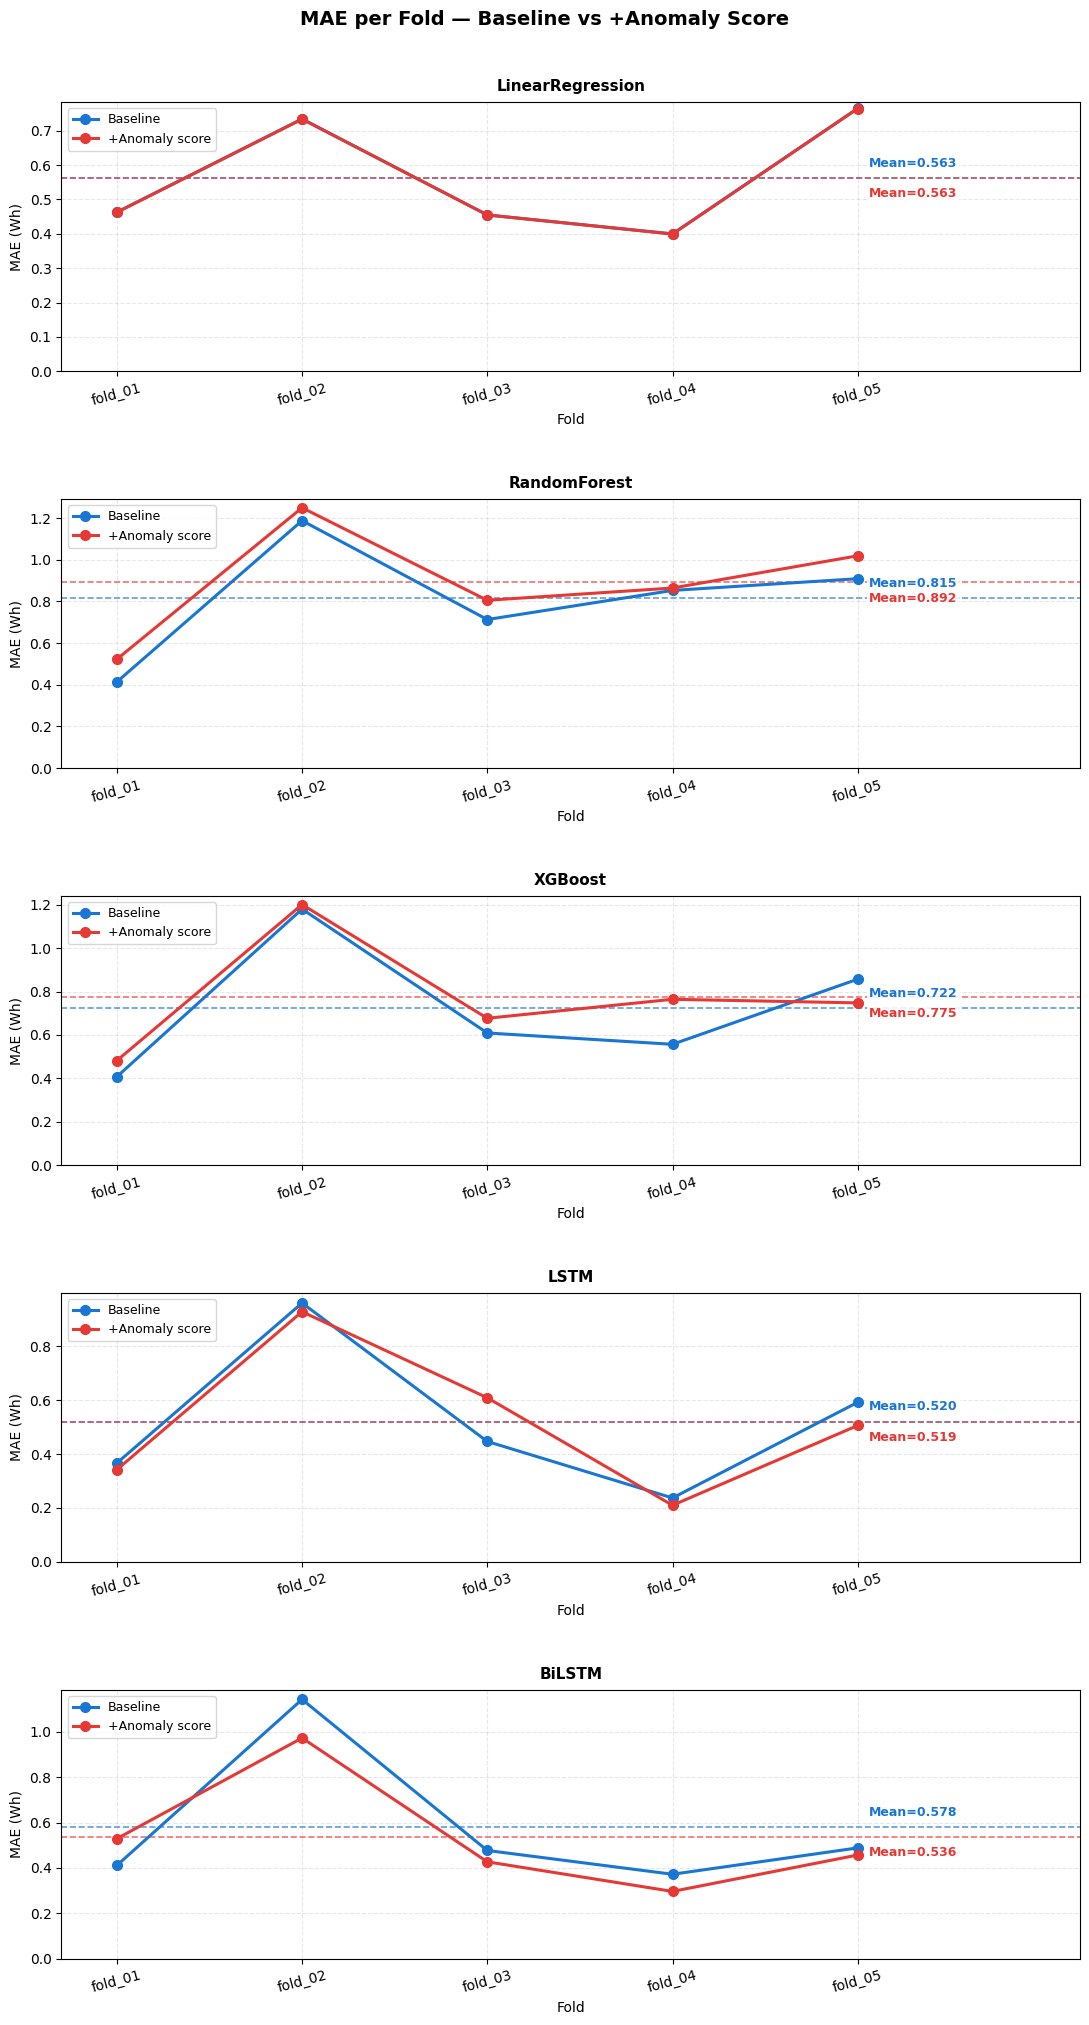

Saved.


<Figure size 640x480 with 0 Axes>

In [ ]:
MODELS = ['LinearRegression', 'RandomForest', 'XGBoost', 'LSTM', 'BiLSTM']
COLORS = {'baseline': '#1976D2', 'with_anomaly': '#E53935'}
LABELS = {'baseline': 'Baseline', 'with_anomaly': '+Anomaly score'}

fig, axes = plt.subplots(len(MODELS), 1, figsize=(11, 4*len(MODELS)))
fig.suptitle('MAE per Fold — Baseline vs +Anomaly Score',
             fontsize=14, fontweight='bold', y=1.01)

for ax, model in zip(axes, MODELS):
    for cond in ['baseline', 'with_anomaly']:
        sub = df_all[(df_all['model']==model)&(df_all['condition']==cond)]\
              .sort_values('fold').reset_index(drop=True)
        if sub.empty:
            continue
        x    = np.arange(1, len(sub)+1)
        mae  = sub['MAE'].values
        mean_mae = mae.mean()

        ax.plot(x, mae, marker='o', linewidth=2.2, markersize=7,
                color=COLORS[cond], label=LABELS[cond], zorder=3)
        ax.axhline(mean_mae, color=COLORS[cond], linewidth=1.2,
                   linestyle='--', alpha=0.7, zorder=2)
        offset = 8 if cond == 'baseline' else -14
        ax.annotate(f'Mean={mean_mae:.3f}',
                    xy=(len(sub), mean_mae),
                    xytext=(8, offset),
                    textcoords='offset points',
                    color=COLORS[cond], fontsize=9, fontweight='bold',
                    bbox={'facecolor':'white','edgecolor':'none','alpha':0.85,'pad':1.5},
                    clip_on=False)

    ax.set_title(model, fontsize=11, fontweight='bold', pad=8)
    ax.set_xlabel('Fold')
    ax.set_ylabel('MAE (Wh)')
    ax.set_xticks(range(1, 6))
    ax.set_xticklabels(FOLDS, rotation=15)
    ax.set_xlim(0.7, 6.2)
    ax.set_ylim(bottom=0)
    ax.grid(axis='both', linestyle='--', alpha=0.3)
    ax.legend(fontsize=9, loc='upper left')

plt.tight_layout(h_pad=3.5)
plt.show()
plt.savefig(PLOT_DIR / 'mae_per_fold_all_models.png', dpi=150, bbox_inches='tight')
print('Saved.')

# Boxplot normal vs abnormal

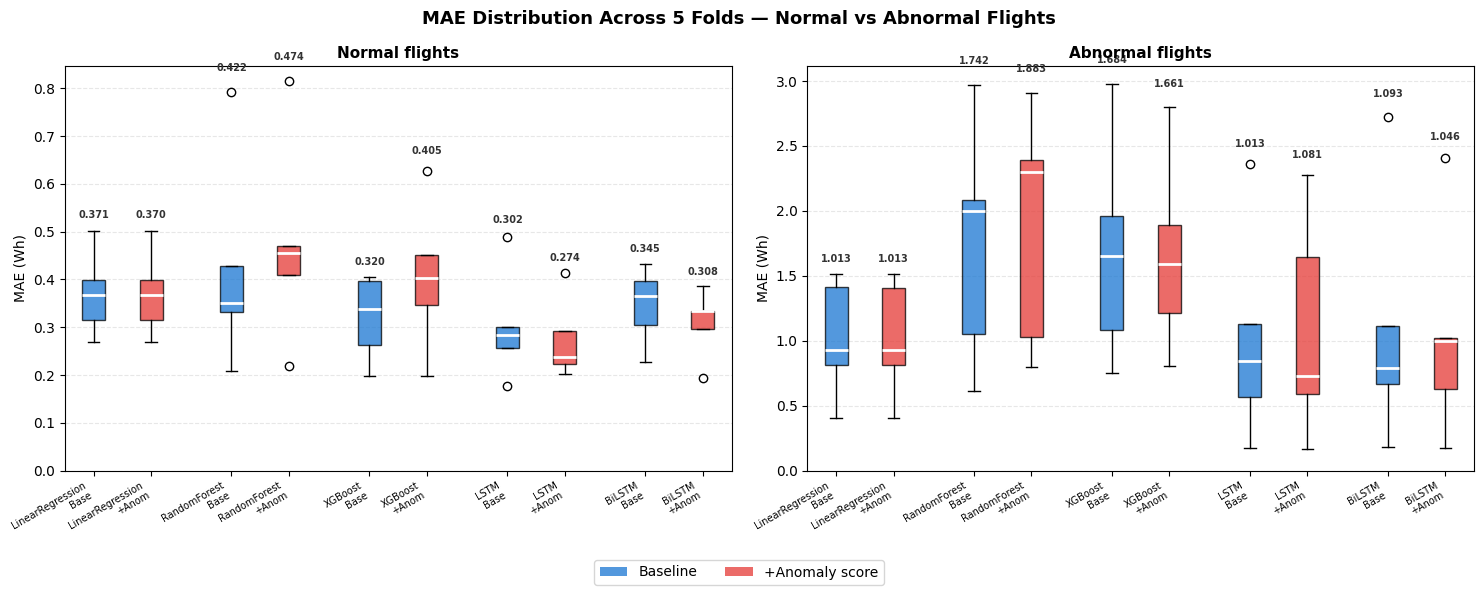

Saved.


<Figure size 640x480 with 0 Axes>

In [ ]:
from matplotlib.patches import Patch

MODELS = ['LinearRegression', 'RandomForest', 'XGBoost', 'LSTM', 'BiLSTM']
COLORS = {'baseline': '#1976D2', 'with_anomaly': '#E53935'}

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
fig.suptitle('MAE Distribution Across 5 Folds — Normal vs Abnormal Flights',
             fontsize=13, fontweight='bold')

for ax, (flight_col, flight_label) in zip(axes, [
    ('MAE_normal',   'Normal flights'),
    ('MAE_abnormal', 'Abnormal flights'),
]):
    data_all, positions, tick_labels, colors_list = [], [], [], []
    pos = 0

    for model in MODELS:
        for cond in ['baseline', 'with_anomaly']:
            sub = df_all[(df_all['model']==model)&(df_all['condition']==cond)][flight_col].dropna()
            if sub.empty:
                continue
            data_all.append(sub.values)
            positions.append(pos)
            tick_labels.append(f'{model}\n{"Base" if cond=="baseline" else "+Anom"}')
            colors_list.append(COLORS[cond])
            pos += 1
        pos += 0.4  # gap between models

    bp = ax.boxplot(data_all, positions=positions, patch_artist=True,
                    notch=False, widths=0.4, showfliers=True)
    for patch, color in zip(bp['boxes'], colors_list):
        patch.set_facecolor(color)
        patch.set_alpha(0.75)
    for median in bp['medians']:
        median.set_color('white')
        median.set_linewidth(2)

    # mean labels above each box
    for pos_i, data_i in zip(positions, data_all):
        ax.text(pos_i, np.max(data_i) * 1.05, f'{np.mean(data_i):.3f}',
                ha='center', va='bottom', fontsize=7,
                fontweight='bold', color='#333333')

    ax.set_xticks(positions)
    ax.set_xticklabels(tick_labels, fontsize=7, rotation=30, ha='right')
    ax.set_ylabel('MAE (Wh)')
    ax.set_title(flight_label, fontsize=11, fontweight='bold')
    ax.set_ylim(bottom=0)
    ax.grid(axis='y', linestyle='--', alpha=0.3)

legend_elements = [
    Patch(facecolor='#1976D2', alpha=0.75, label='Baseline'),
    Patch(facecolor='#E53935', alpha=0.75, label='+Anomaly score'),
]
fig.legend(handles=legend_elements, loc='lower center', ncol=2,
           fontsize=10, bbox_to_anchor=(0.5, 0.01))
plt.tight_layout(rect=[0, 0.07, 1, 1])
plt.show()
plt.savefig(PLOT_DIR / 'mae_boxplot_normal_vs_abnormal.png', dpi=150, bbox_inches='tight')
print('Saved.')

# per-flight timeline

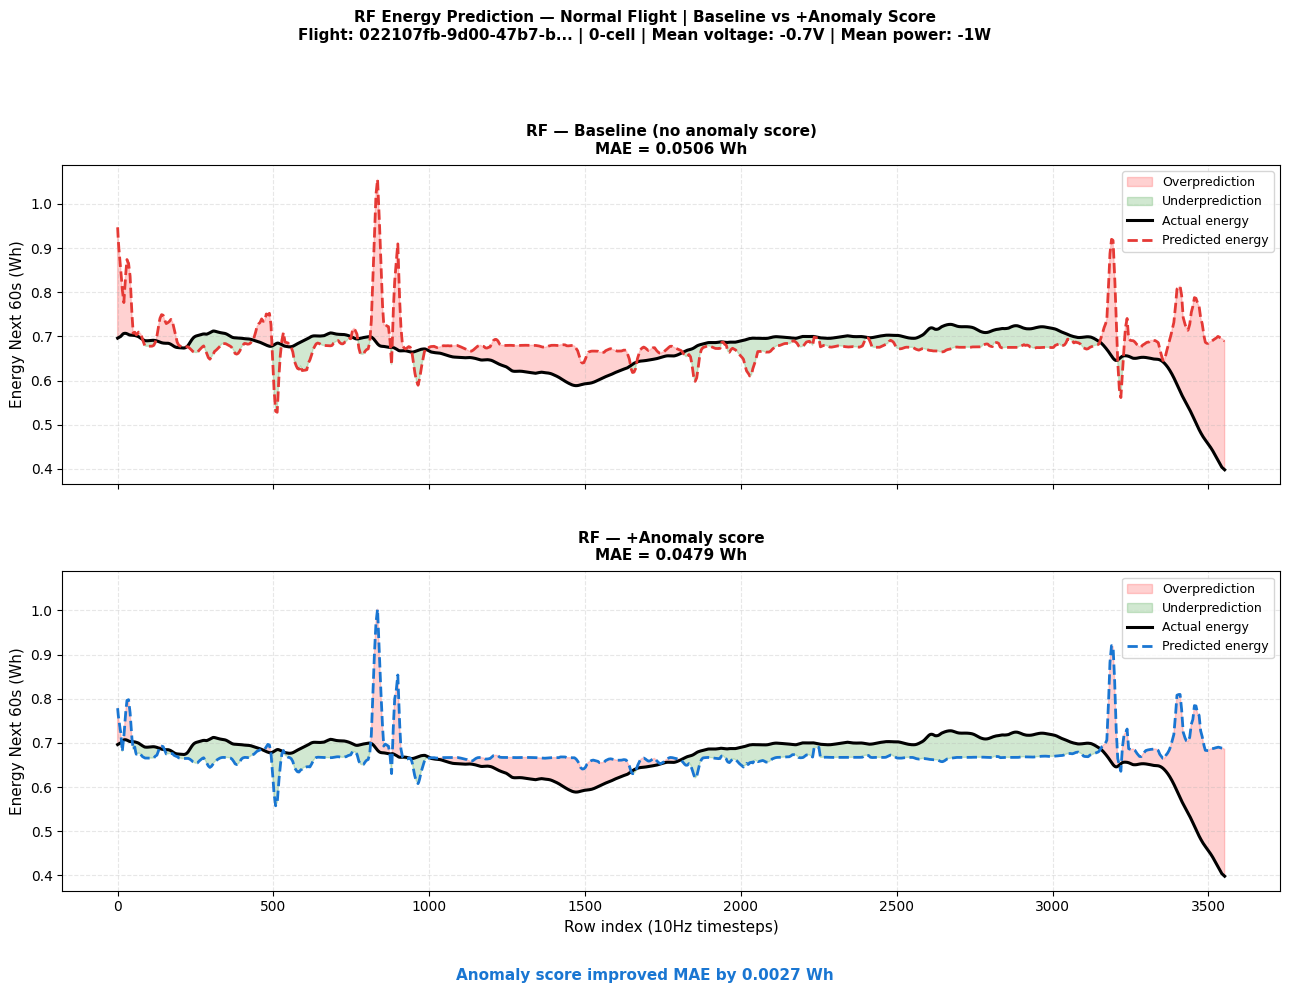

Saved: flight_timeline_fold_01_022107fb_Normal.png | base=0.0506 anom=0.0479 delta=+0.0027


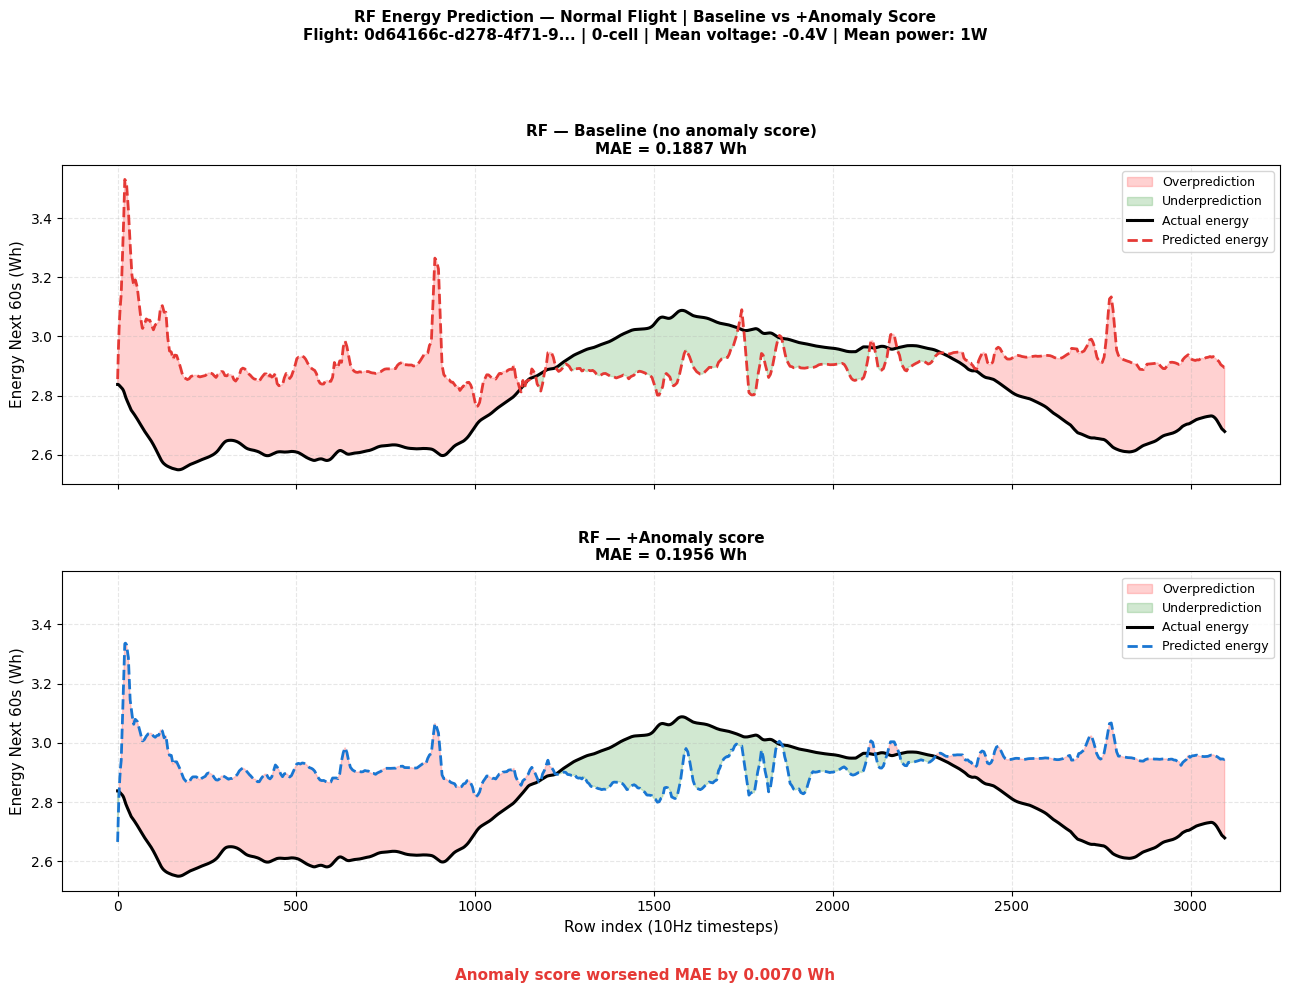

Saved: flight_timeline_fold_01_0d64166c_Normal.png | base=0.1887 anom=0.1956 delta=-0.0070


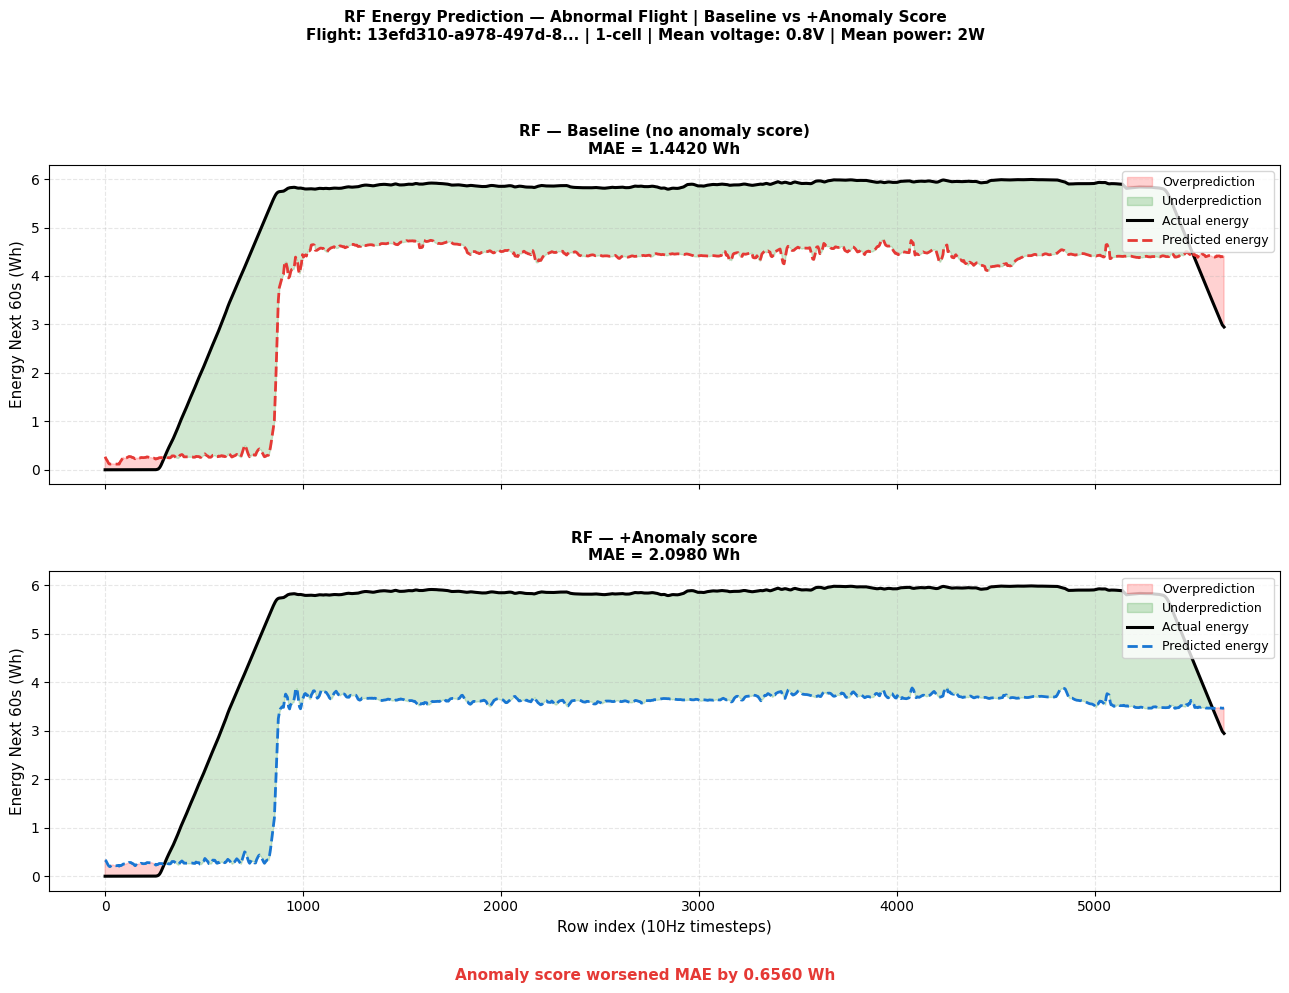

Saved: flight_timeline_fold_01_13efd310_Abnormal.png | base=1.4420 anom=2.0980 delta=-0.6560


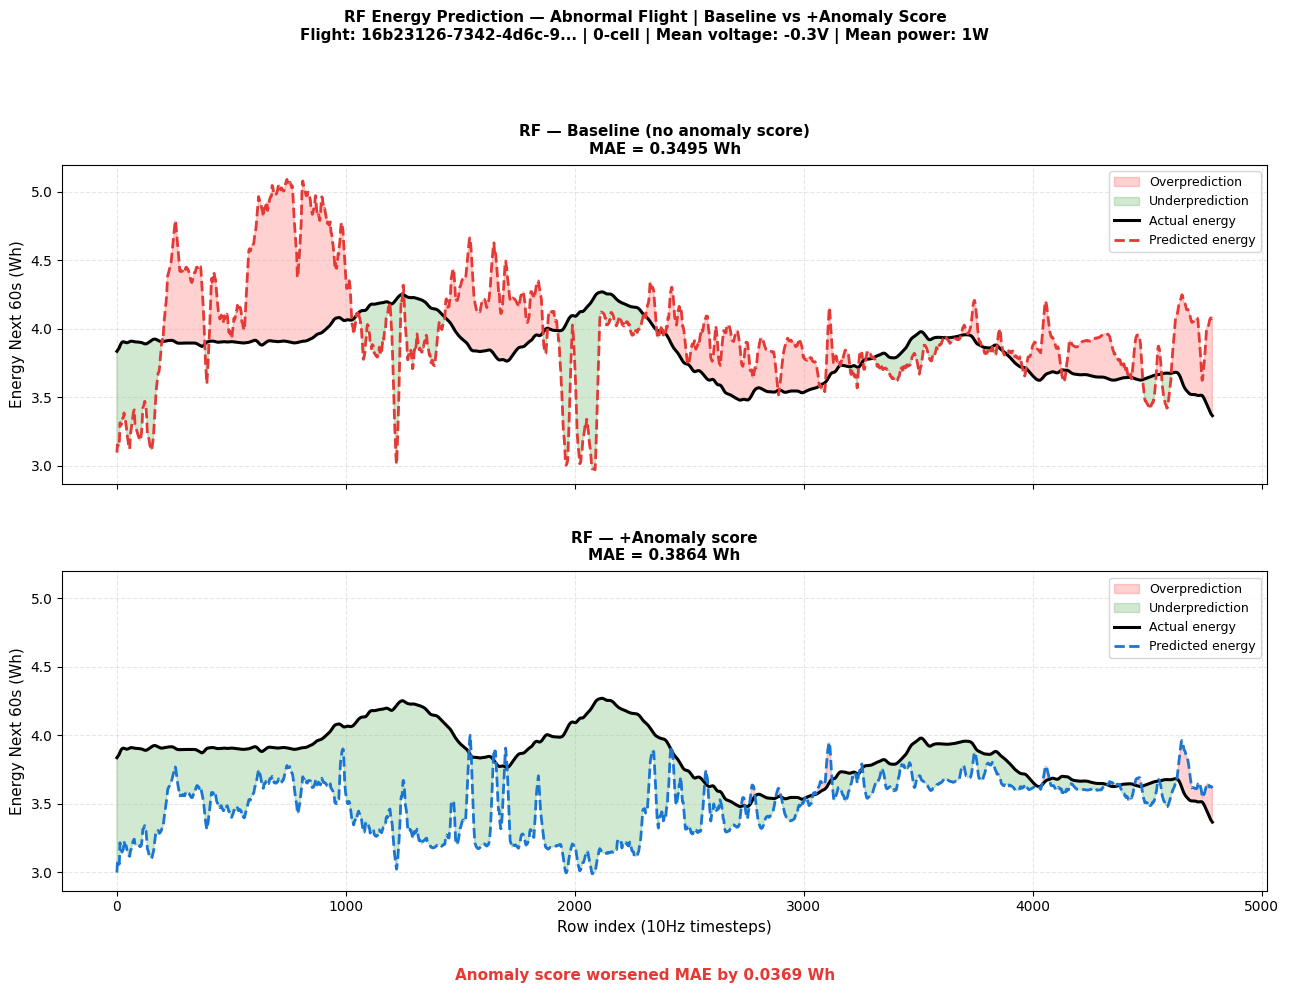

Saved: flight_timeline_fold_01_16b23126_Abnormal.png | base=0.3495 anom=0.3864 delta=-0.0369


In [ ]:
def plot_flight_comparison(fold, flight_id, flight_label):
    fc_clean = [c for c in enriched[fold]['feature_cols'] if c != 'anomaly_flag']
    df_te    = enriched[fold]['test']
    df_tr    = pd.concat([enriched[fold]['train'],
                          enriched[fold]['val']], ignore_index=True)

    grp    = df_te[df_te['log_id'] == flight_id].reset_index(drop=True)
    t      = np.arange(len(grp))
    y_true = grp[TARGET].values

    preds = {}
    for use_anomaly in [False, True]:
        cols = fc_clean + (['anomaly_score'] if use_anomaly else [])
        X_tr = df_tr[cols].values.astype(np.float32)
        y_tr = df_tr[TARGET].values.astype(np.float32)
        mdl  = RandomForestRegressor(n_estimators=100, max_depth=15,
                                     min_samples_leaf=10, max_features=0.5,
                                     n_jobs=-1, random_state=42)
        mdl.fit(X_tr, y_tr)
        preds[use_anomaly] = mdl.predict(grp[cols].values.astype(np.float32))

    def smooth(v, w=20):
        return pd.Series(v).rolling(w, center=True, min_periods=1).mean().values

    y_true_s = smooth(y_true)
    y_base_s = smooth(preds[False])
    y_anom_s = smooth(preds[True])

    mae_base = mean_absolute_error(y_true, preds[False])
    mae_anom = mean_absolute_error(y_true, preds[True])
    improvement = mae_base - mae_anom

    fig, axes = plt.subplots(2, 1, figsize=(13, 10), sharex=True, sharey=True)

    voltage = grp['battery_status__voltage_v'].mean() if 'battery_status__voltage_v' in grp.columns else None
    power   = grp['power_w'].mean() if 'power_w' in grp.columns else None
    cells   = int(grp['battery_status__cell_count'].median()) if 'battery_status__cell_count' in grp.columns else '?'

    info = f'Flight: {flight_id[:20]}... | {cells}-cell'
    if voltage: info += f' | Mean voltage: {voltage:.1f}V'
    if power:   info += f' | Mean power: {power:.0f}W'

    fig.suptitle(f'RF Energy Prediction — {flight_label} Flight | '
                 f'Baseline vs +Anomaly Score\n{info}',
                 fontsize=11, fontweight='bold')

    for ax, y_pred_s, color, title, mae in [
        (axes[0], y_base_s, '#E53935', 'RF — Baseline (no anomaly score)', mae_base),
        (axes[1], y_anom_s, '#1976D2', 'RF — +Anomaly score',              mae_anom),
    ]:
        ax.fill_between(t, y_pred_s, y_true_s,
                        where=y_pred_s > y_true_s,
                        color='red', alpha=0.18, interpolate=True,
                        label='Overprediction')
        ax.fill_between(t, y_pred_s, y_true_s,
                        where=y_pred_s < y_true_s,
                        color='green', alpha=0.18, interpolate=True,
                        label='Underprediction')
        ax.plot(t, y_true_s, 'k-', lw=2.2, label='Actual energy', zorder=3)
        ax.plot(t, y_pred_s, color=color, lw=2, linestyle='--',
                label='Predicted energy', zorder=3)
        ax.set_title(f'{title}\nMAE = {mae:.4f} Wh',
                     fontsize=11, fontweight='bold', pad=8)
        ax.set_ylabel('Energy Next 60s (Wh)', fontsize=11)
        ax.grid(axis='both', linestyle='--', alpha=0.3)
        ax.legend(fontsize=9, loc='upper right')

    axes[-1].set_xlabel('Row index (10Hz timesteps)', fontsize=11)

    summary_color = '#1976D2' if improvement > 0 else '#E53935'
    summary_text  = (f'Anomaly score improved MAE by {improvement:.4f} Wh'
                     if improvement > 0 else
                     f'Anomaly score worsened MAE by {abs(improvement):.4f} Wh')
    fig.text(0.5, 0.01, summary_text, ha='center', fontsize=11,
             fontweight='bold', color=summary_color)

    plt.tight_layout(rect=[0, 0.04, 1, 0.93], h_pad=3.0)
    plt.show()
    fname = PLOT_DIR / f'flight_timeline_{fold}_{flight_id[:8]}_{flight_label}.png'
    plt.savefig(fname, dpi=150, bbox_inches='tight')
    plt.close()
    print(f'Saved: {fname.name} | base={mae_base:.4f} anom={mae_anom:.4f} delta={improvement:+.4f}')


# 2 normal + 2 abnormal from fold_01
df_te_01     = enriched['fold_01']['test']
normal_ids   = df_te_01[df_te_01['dataset_label']=='normal']['log_id'].unique()[:2]
abnormal_ids = df_te_01[df_te_01['dataset_label']=='abnormal']['log_id'].unique()[:2]

for fid in normal_ids:
    plot_flight_comparison('fold_01', fid, 'Normal')
for fid in abnormal_ids:
    plot_flight_comparison('fold_01', fid, 'Abnormal')

# SHAP for all tree models


=== SHAP: LinearRegression ===


  anomaly_score rank : 17 of 17
  |SHAP| normal      : 0.001645
  |SHAP| abnormal    : 0.001636


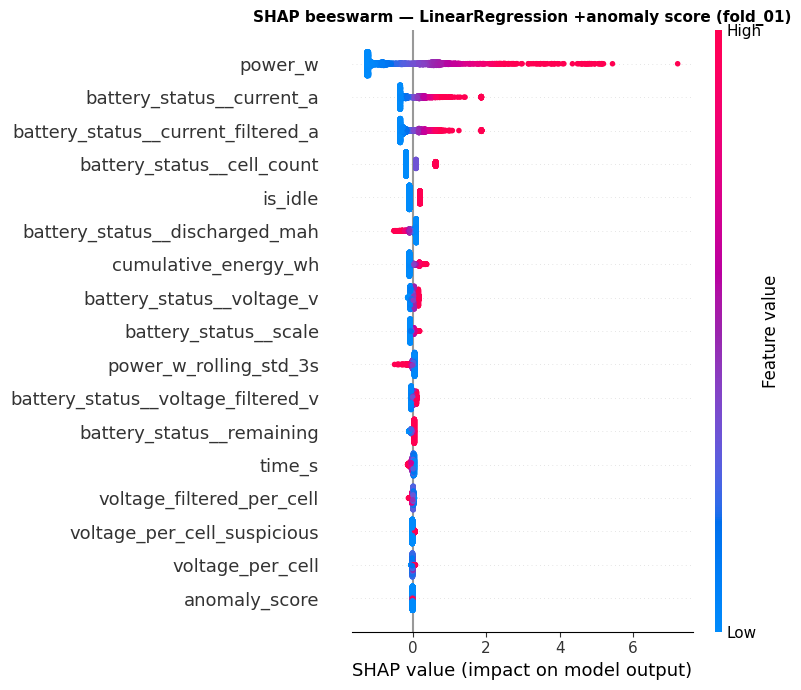

  Saved: shap_beeswarm_linearregression.png

=== SHAP: RandomForest ===
  anomaly_score rank : 3 of 17
  |SHAP| normal      : 0.295483
  |SHAP| abnormal    : 0.357155


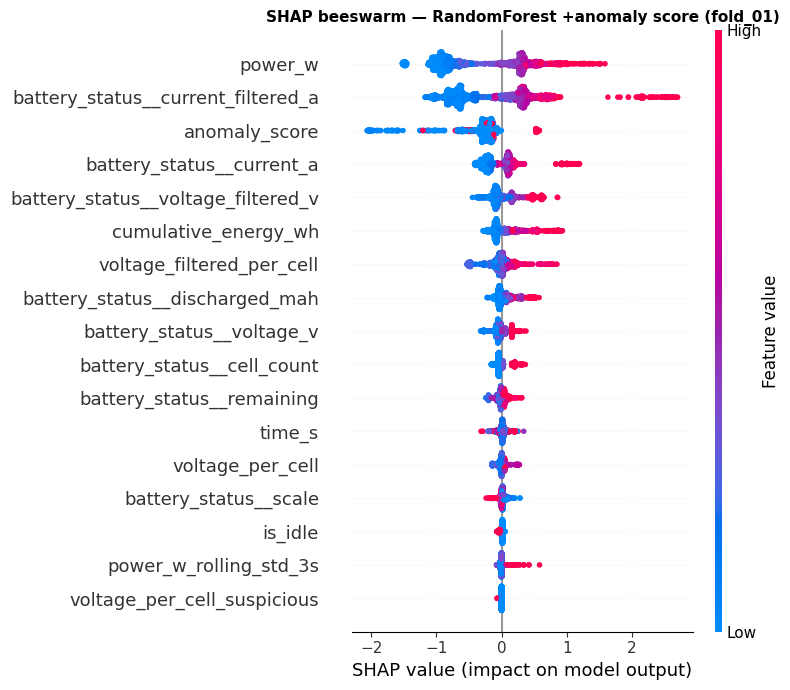

  Saved: shap_beeswarm_randomforest.png

=== SHAP: XGBoost ===
  anomaly_score rank : 3 of 17
  |SHAP| normal      : 0.371283
  |SHAP| abnormal    : 0.379866


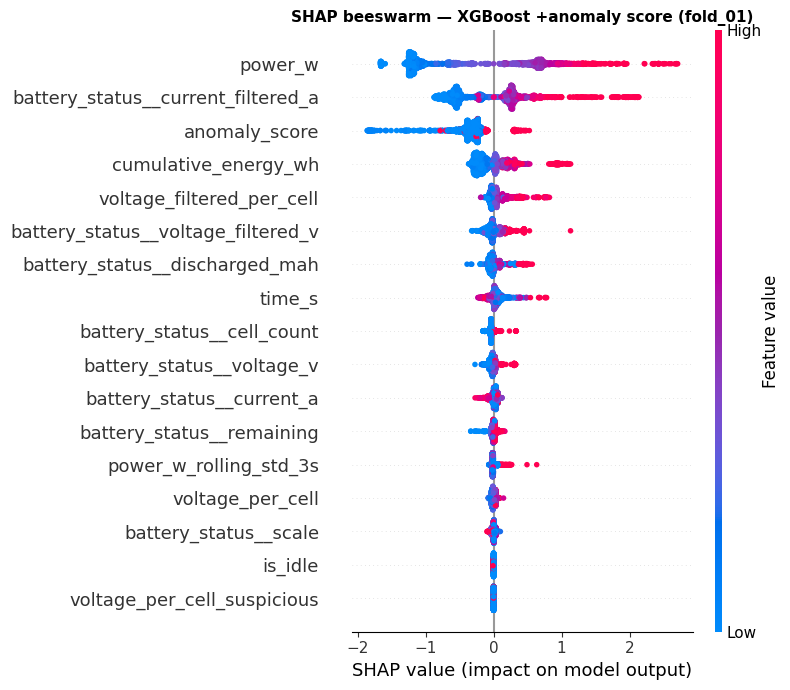

  Saved: shap_beeswarm_xgboost.png


In [ ]:
for model_name in ['LinearRegression', 'RandomForest', 'XGBoost']:
    print(f'\n=== SHAP: {model_name} ===')

    fold     = 'fold_01'
    fc_clean = [c for c in enriched[fold]['feature_cols'] if c != 'anomaly_flag']
    cols     = fc_clean + ['anomaly_score']

    df_tr = pd.concat([enriched[fold]['train'],
                       enriched[fold]['val']], ignore_index=True)
    df_va = enriched[fold]['val']
    df_te = enriched[fold]['test']

    X_tr = df_tr[cols].values.astype(np.float32)
    y_tr = df_tr[TARGET].values.astype(np.float32)
    X_va = df_va[cols].values.astype(np.float32)
    y_va = df_va[TARGET].values.astype(np.float32)
    X_te = df_te[cols].values.astype(np.float32)

    if model_name == 'XGBoost':
        mdl = XGBRegressor(n_estimators=1000, max_depth=5, learning_rate=0.01,
                           min_child_weight=10, subsample=0.8, colsample_bytree=0.8,
                           early_stopping_rounds=50, random_state=42,
                           verbosity=0, n_jobs=-1)
        mdl.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], verbose=False)
        explainer = shap.TreeExplainer(mdl)

    elif model_name == 'RandomForest':
        mdl = RandomForestRegressor(n_estimators=300, max_depth=15,
                                    min_samples_leaf=10, max_features=0.5,
                                    n_jobs=-1, random_state=42)
        mdl.fit(X_tr, y_tr)
        explainer = shap.TreeExplainer(mdl)

    else:  # LinearRegression
        mdl = LinearRegression()
        mdl.fit(X_tr, y_tr)
        explainer = shap.LinearExplainer(mdl, X_tr)

    idx       = np.random.choice(len(X_te), min(2000, len(X_te)), replace=False)
    shap_vals = explainer.shap_values(X_te[idx])

    assert shap_vals.shape[1] == len(cols), \
        f'Mismatch: {shap_vals.shape[1]} vs {len(cols)}'

    # rank of anomaly_score
    anom_idx = cols.index('anomaly_score')
    rank     = np.argsort(np.abs(shap_vals).mean(0))[::-1].tolist().index(anom_idx) + 1
    print(f'  anomaly_score rank : {rank} of {len(cols)}')

    # normal vs abnormal SHAP
    normal_idx   = np.where(df_te['dataset_label'].values[idx] == 'normal')[0]
    abnormal_idx = np.where(df_te['dataset_label'].values[idx] == 'abnormal')[0]
    print(f'  |SHAP| normal      : {np.abs(shap_vals[normal_idx,   anom_idx]).mean():.6f}')
    print(f'  |SHAP| abnormal    : {np.abs(shap_vals[abnormal_idx, anom_idx]).mean():.6f}')

    shap.summary_plot(shap_vals, X_te[idx], feature_names=cols,
                      show=False, plot_size=(8, 7))
    plt.title(f'SHAP beeswarm — {model_name} +anomaly score (fold_01)',
              fontsize=11, fontweight='bold')
    plt.tight_layout()
    plt.savefig(PLOT_DIR / f'shap_beeswarm_{model_name.lower()}.png',
                dpi=150, bbox_inches='tight')
    plt.show()
    print(f'  Saved: shap_beeswarm_{model_name.lower()}.png')

# SHAP for all sequence models

In [ ]:
class ModelWrapper(torch.nn.Module):
    def __init__(self, model):
        super().__init__()
        self.model = model

    def forward(self, x):
        out = self.model(x)
        if out.dim() == 1:
            out = out.unsqueeze(1)
        return out

    def train(self, mode=True):
        super().train(mode)
        for module in self.model.modules():
            if isinstance(module, torch.nn.Dropout):
                module.eval()
        return self

for arch, bidir in [('LSTM', False), ('BiLSTM', True)]:
    print(f'\n=== SHAP: {arch} ===')

    fold     = 'fold_01'
    fc_clean = [c for c in enriched[fold]['feature_cols'] if c != 'anomaly_flag']
    cols     = fc_clean + ['anomaly_score']
    n_feat   = len(cols)

    df_tr = enriched[fold]['train']
    df_te = enriched[fold]['test']

    X_tr, y_tr = make_sequences(df_tr, cols, TARGET, WINDOW, STRIDE)
    X_te, y_te = make_sequences(df_te, cols, TARGET, WINDOW, STRIDE)

    cond_str = 'anom'
    ckpt = OUT_DIR / f'{arch.lower()}_fold_01_{cond_str}.pt'
    base_model = LSTMRegressor(n_feat, hidden=128, layers=2,
                               dropout=0.2, bidirectional=bidir).to(DEVICE)
    base_model.load_state_dict(torch.load(ckpt, map_location=DEVICE))

    model = ModelWrapper(base_model).to(DEVICE)
    model.train()

    bg_idx  = np.random.choice(len(X_tr), 200, replace=False)
    bg_data = torch.tensor(X_tr[bg_idx], dtype=torch.float32).to(DEVICE)

    te_idx  = np.random.choice(len(X_te), min(500, len(X_te)), replace=False)
    te_data = torch.tensor(X_te[te_idx], dtype=torch.float32).to(DEVICE)

    explainer = shap.GradientExplainer(model, bg_data)
    shap_vals = explainer.shap_values(te_data)

    if isinstance(shap_vals, list):
        shap_vals = shap_vals[0]

    shap_mean  = np.abs(shap_vals).mean(axis=1)
    global_imp = shap_mean.mean(axis=0)
    anom_idx   = cols.index('anomaly_score')
    rank       = np.argsort(global_imp)[::-1].tolist().index(anom_idx) + 1

    print(f'  anomaly_score rank : {rank} of {len(cols)}')
    print(f'  Mean |SHAP| anomaly_score: {shap_mean[:, anom_idx].mean():.6f}')
    print(f'  Top 5 features by mean |SHAP|:')
    top5 = np.argsort(global_imp)[::-1][:5]
    for i in top5:
        print(f'    {cols[i]:40s} {global_imp[i]:.6f}')

    order      = np.argsort(global_imp)
    colors_bar = ['#E8593C' if c == 'anomaly_score' else '#4A90D9'
                  for c in [cols[i] for i in order]]

    fig, ax = plt.subplots(figsize=(8, 7))
    ax.barh(range(len(cols)), global_imp[order],
            color=colors_bar, alpha=0.85)
    ax.set_yticks(range(len(cols)))
    ax.set_yticklabels([cols[i] for i in order], fontsize=9)
    ax.set_xlabel('Mean |SHAP| value (averaged over time and samples)')
    ax.set_title(f'SHAP feature importance — {arch} +anomaly score (fold_01)\n'
                 f'Orange = anomaly_score (rank {rank} of {len(cols)})',
                 fontsize=11, fontweight='bold')
    ax.grid(axis='x', linestyle='--', alpha=0.3)
    plt.tight_layout()
    plt.savefig(PLOT_DIR / f'shap_bar_{arch.lower()}.png',
                dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()
    print(f'  Saved: shap_bar_{arch.lower()}.png')


=== SHAP: LSTM ===


RuntimeError: cudnn RNN backward can only be called in training mode

In [ ]:
#to recompute RFT using median of active (power_w > 0) rows per fold
print('=== RFT error fix — using median active power_w ===')
for fold in FOLDS:
    df_te = enriched[fold]['test']
    active_pw = df_te[df_te['power_w'] > 0]['power_w']
    print(f'{fold} | active rows={len(active_pw)} | median_active_pw={active_pw.median():.4f}')

=== RFT error fix — using median active power_w ===
fold_01 | active rows=88889 | median_active_pw=0.8409
fold_02 | active rows=89374 | median_active_pw=1.0178
fold_03 | active rows=113000 | median_active_pw=0.7387
fold_04 | active rows=57791 | median_active_pw=0.7031
fold_05 | active rows=107214 | median_active_pw=1.1628


# RFT per fold per model

=== RFT error (seconds) — fixed ===
           model    condition    RFT_mean     RFT_std
LinearRegression     baseline 2242.323091  249.475315
LinearRegression with_anomaly 2241.079197  249.665019
    RandomForest     baseline 3325.366552 1066.138780
    RandomForest with_anomaly 3632.263575  936.566672
         XGBoost     baseline 2879.463043  870.450775
         XGBoost with_anomaly 3168.852185  960.916931
            LSTM     baseline 2037.084133  836.554561
            LSTM with_anomaly 2070.221329  984.208798
          BiLSTM     baseline 2308.213155 1010.825973
          BiLSTM with_anomaly 2143.447099  808.136477


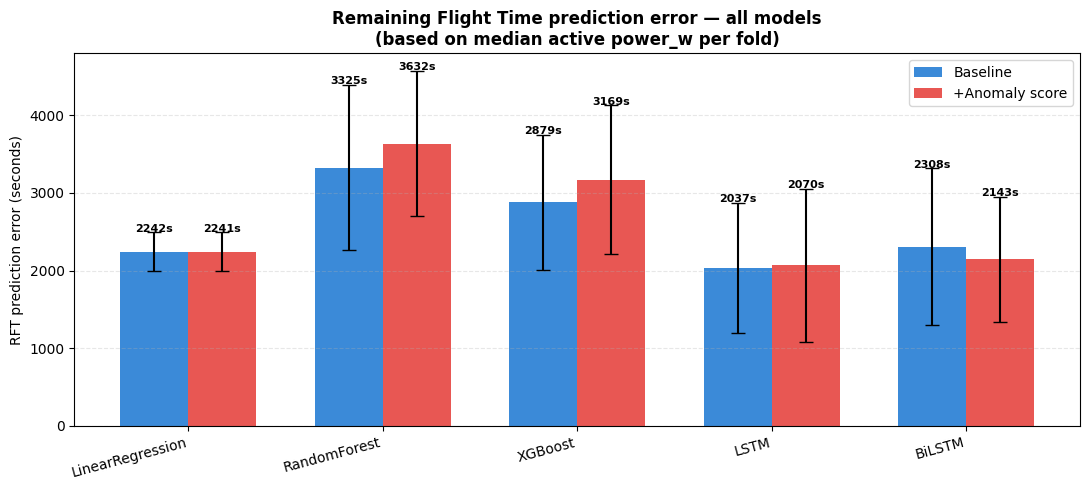

Saved.


<Figure size 640x480 with 0 Axes>

In [ ]:
MODELS = ['LinearRegression', 'RandomForest', 'XGBoost', 'LSTM', 'BiLSTM']

# build active power lookup
active_pw = {}
for fold in FOLDS:
    df_te = enriched[fold]['test']
    pw = df_te[df_te['power_w'] > 0]['power_w']
    active_pw[fold] = pw.median()

# recompute RFT for every row in df_all
def rft_from_mae(mae, power_w):
    if power_w and power_w > 0:
        return (mae / power_w) * 3600
    return np.nan

df_all['RFT_err_s_fixed'] = df_all.apply(
    lambda r: rft_from_mae(r['MAE'], active_pw.get(r['fold'], None)), axis=1
)

# rebuild summary with fixed RFT
rft_summary = []
for model in MODELS:
    for cond in ['baseline', 'with_anomaly']:
        sub = df_all[(df_all['model']==model)&(df_all['condition']==cond)]
        if sub.empty:
            continue
        rft_summary.append({
            'model'      : model,
            'condition'  : cond,
            'RFT_mean'   : sub['RFT_err_s_fixed'].mean(),
            'RFT_std'    : sub['RFT_err_s_fixed'].std(),
        })

df_rft = pd.DataFrame(rft_summary)

print('=== RFT error (seconds) — fixed ===')
print(df_rft.to_string(index=False))

# ── plot ───────────────────────────────────────────────────────────────────
COLORS = {'baseline': '#1976D2', 'with_anomaly': '#E53935'}

fig, ax = plt.subplots(figsize=(11, 5))
x = np.arange(len(MODELS))
w = 0.35

for i, cond in enumerate(['baseline', 'with_anomaly']):
    sub   = df_rft[df_rft['condition'] == cond]
    means = [sub[sub['model']==m]['RFT_mean'].values[0]
             if len(sub[sub['model']==m]) > 0 else np.nan for m in MODELS]
    stds  = [sub[sub['model']==m]['RFT_std'].values[0]
             if len(sub[sub['model']==m]) > 0 else np.nan for m in MODELS]

    bars = ax.bar(x + (i-0.5)*w, means, w, yerr=stds,
                  capsize=5, color=COLORS[cond], alpha=0.85,
                  label='Baseline' if cond=='baseline' else '+Anomaly score')

    # value labels on bars
    for xi, (bar, mean) in enumerate(zip(bars, means)):
        if not np.isnan(mean):
            ax.text(bar.get_x() + bar.get_width()/2,
                    mean + (stds[xi] if not np.isnan(stds[xi]) else 0) + 5,
                    f'{mean:.0f}s', ha='center', fontsize=8, fontweight='bold')

ax.set_xticks(x)
ax.set_xticklabels(MODELS, rotation=15, ha='right')
ax.set_ylabel('RFT prediction error (seconds)')
ax.set_title('Remaining Flight Time prediction error — all models\n'
             '(based on median active power_w per fold)',
             fontsize=12, fontweight='bold')
ax.set_ylim(bottom=0)
ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()
plt.savefig(PLOT_DIR / 'rft_error_fixed.png', dpi=150, bbox_inches='tight')
print('Saved.')

In [ ]:


all_raw_test = pd.concat([
    pd.read_parquet(
        raw_dir / fold / f'test_no_dr_interpolated_v5_voltage_kfold5_{fold}.parquet'
    ).assign(fold=fold)
    for fold in FOLDS
])

print(f"Raw test rows: {len(all_raw_test)}")
print(f"power_w stats:\n{all_raw_test['power_w'].describe().round(2)}")
print(f"is_idle value counts:\n{all_raw_test['is_idle'].value_counts()}")

active_raw = all_raw_test[all_raw_test['is_idle'] == 0]
print(f"\nActive rows: {len(active_raw)}")

fold_power = active_raw.groupby('fold')['power_w'].mean()
print("\nMean active-phase power per fold (W):")
print(fold_power.round(2))

MEAN_ACTIVE_POWER_W = active_raw['power_w'].mean()
print(f"\nOverall mean active-phase power: {MEAN_ACTIVE_POWER_W:.2f} W")

df_all = pd.read_parquet(OUT_DIR / 'all_results.parquet')

records = []
for _, row in df_all.iterrows():
    fold_pw = fold_power.get(row['fold'], MEAN_ACTIVE_POWER_W)
    for label, mae_col in [('normal', 'MAE_normal'), ('abnormal', 'MAE_abnormal'), ('all', 'MAE')]:
        mae = row[mae_col]
        rft = (mae / fold_pw) * 3600
        records.append({
            'Model'         : row['model'],
            'Fold'          : row['fold'],
            'Condition'     : row['condition'],
            'Label'         : label,
            'MAE (Wh)'      : round(mae, 4),
            'RFT error (s)' : round(rft, 1),
        })

df_rft = pd.DataFrame(records)

grouped = (
    df_rft.groupby(['Model', 'Condition', 'Label'])[['MAE (Wh)', 'RFT error (s)']]
    .mean()
    .round(3)
    .reset_index()
)

pivot = grouped.pivot_table(
    index=['Model', 'Label'],
    columns='Condition',
    values=['MAE (Wh)', 'RFT error (s)']
).round(3)

pivot.columns = [f'{v} {c}' for v, c in pivot.columns]
pivot['ΔMAE (Wh)'] = (pivot['MAE (Wh) with_anomaly']     - pivot['MAE (Wh) baseline']).round(4)
pivot['ΔRFT (s)']  = (pivot['RFT error (s) with_anomaly'] - pivot['RFT error (s) baseline']).round(1)

pivot = pivot.rename(columns={
    'MAE (Wh) baseline'          : 'MAE baseline (Wh)',
    'MAE (Wh) with_anomaly'      : 'MAE +anomaly (Wh)',
    'RFT error (s) baseline'     : 'RFT baseline (s)',
    'RFT error (s) with_anomaly' : 'RFT +anomaly (s)',
})

print("\n=== Five-fold mean MAE and RFT error — all models, all labels ===")
print(pivot.to_string())
pivot.to_csv(OUT_DIR / 'rft_mae_full_comparison.csv')
print("\nSaved: rft_mae_full_comparison.csv")

Raw test rows: 966925
power_w stats:
count    966925.00
mean        140.60
std         216.80
min           0.00
25%           5.88
50%          78.14
75%         185.70
max        2760.50
Name: power_w, dtype: float64
is_idle value counts:
is_idle
0.0    696184
1.0    270741
Name: count, dtype: int64

Active rows: 696184

Mean active-phase power per fold (W):
fold
fold_01    168.00
fold_02    284.77
fold_03    219.66
fold_04     97.36
fold_05    198.53
Name: power_w, dtype: float64

Overall mean active-phase power: 194.60 W

=== Five-fold mean MAE and RFT error — all models, all labels ===
                           MAE baseline (Wh)  MAE +anomaly (Wh)  RFT baseline (s)  RFT +anomaly (s)  ΔMAE (Wh)  ΔRFT (s)
Model            Label                                                                                                  
BiLSTM           abnormal              1.093              1.046             17.54             17.24     -0.047      -0.3
                 all                   

In [ ]:
import numpy as np
import pandas as pd
from scipy import stats

df_all = pd.read_parquet(OUT_DIR / 'all_results.parquet')
MODELS = ['LinearRegression', 'RandomForest', 'XGBoost', 'LSTM', 'BiLSTM']

rows = []
for model in MODELS:
    base  = df_all[(df_all['model']==model)&(df_all['condition']=='baseline')]\
            .sort_values('fold')['MAE'].values
    anom  = df_all[(df_all['model']==model)&(df_all['condition']=='with_anomaly')]\
            .sort_values('fold')['MAE'].values

    diffs = base - anom
    n     = len(diffs)
    delta = diffs.mean()

    if np.all(diffs == 0):
        w_stat, w_p = np.nan, np.nan
    else:
        w_stat, w_p = stats.wilcoxon(diffs, alternative='greater')

    cohens_d = delta / diffs.std(ddof=1) if diffs.std(ddof=1) > 0 else np.nan

    se    = diffs.std(ddof=1) / np.sqrt(n)
    t_crit = stats.t.ppf(0.975, df=n-1)
    ci_lo = delta - t_crit * se
    ci_hi = delta + t_crit * se

    rows.append({
        'Model'      : model,
        'ΔMAE (Wh)'  : round(delta, 4),
        'Wilcoxon p' : round(w_p, 4) if not np.isnan(w_p) else np.nan,
        "Cohen's d"  : round(cohens_d, 3) if not np.isnan(cohens_d) else np.nan,
        '95% CI low' : round(ci_lo, 4),
        '95% CI high': round(ci_hi, 4),
        'Significant': w_p < 0.05 if not np.isnan(w_p) else False
    })

df_stats = pd.DataFrame(rows)
print(df_stats.to_string(index=False))
df_stats.to_csv(OUT_DIR / 'significance_cohens_ci.csv', index=False)
print('\nSaved.')

           Model  ΔMAE (Wh)  Wilcoxon p  Cohen's d  95% CI low  95% CI high  Significant
LinearRegression     0.0003      0.0312      2.481      0.0002       0.0005         True
    RandomForest    -0.0769      1.0000     -1.861     -0.1282      -0.0256        False
         XGBoost    -0.0522      0.8438     -0.458     -0.1939       0.0894        False
            LSTM     0.0016      0.3125      0.016     -0.1161       0.1193        False
          BiLSTM     0.0418      0.2188      0.403     -0.0871       0.1707        False

Saved.


Features: 17  |  cols sample: ['battery_status__cell_count', 'battery_status__current_a', 'battery_status__current_filtered_a']
X_tr: (66020, 50, 17)  X_te: (18932, 50, 17)

=== SHAP: LSTM ===
  anomaly_score rank    : 17 of 17
  Mean |SHAP| anomaly   : 0.000075
  Top 5 features:
    battery_status__current_filtered_a       0.013124
    cumulative_energy_wh                     0.010214
    power_w                                  0.010022
    battery_status__discharged_mah           0.005661
    time_s                                   0.004121


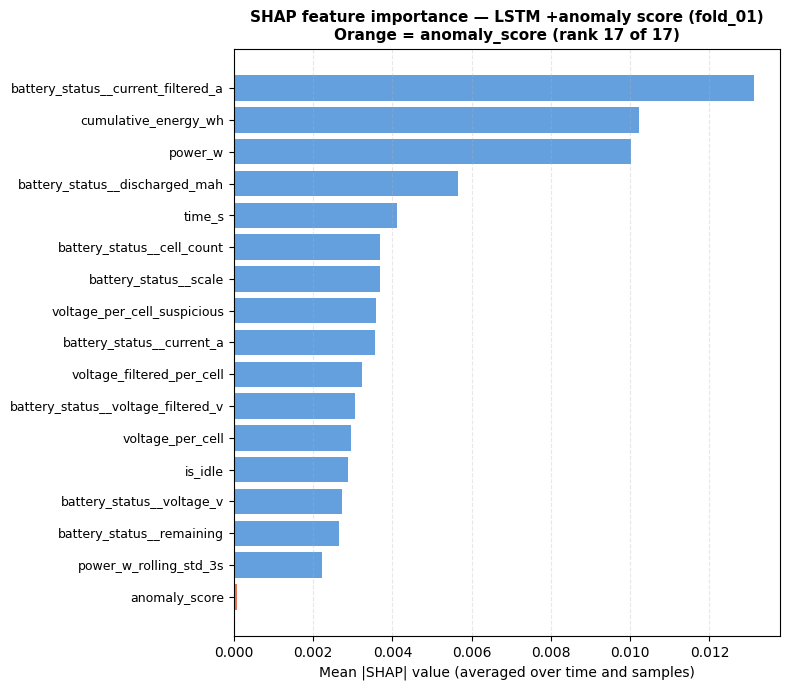

  Saved: shap_bar_lstm.png

=== SHAP: BiLSTM ===
  anomaly_score rank    : 17 of 17
  Mean |SHAP| anomaly   : 0.000086
  Top 5 features:
    battery_status__current_filtered_a       0.015126
    power_w                                  0.011255
    cumulative_energy_wh                     0.009796
    battery_status__voltage_filtered_v       0.006280
    time_s                                   0.005490


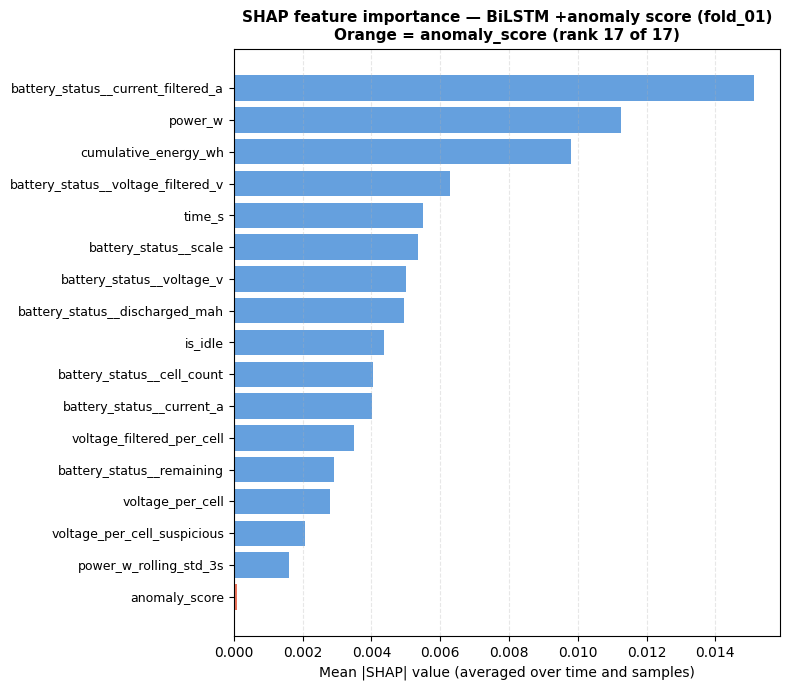

  Saved: shap_bar_bilstm.png


In [8]:
import json, warnings
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.backends
from pathlib import Path
import shap
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')

DEVICE       = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
MODEL_ROOT   = Path('/content/drive/MyDrive/uav_thesis/model_outputs/v2')
ENRICHED_DIR = MODEL_ROOT / 'v3b/07_enriched_parquets'
OUT_DIR      = MODEL_ROOT / '08_anomaly_regression'
PLOT_DIR     = OUT_DIR / 'plots'
PLOT_DIR.mkdir(parents=True, exist_ok=True)

TARGET = 'target_energy_next_60s_wh'
WINDOW = 50
STRIDE = 10
fold   = 'fold_01'

df_tr = pd.read_parquet(ENRICHED_DIR / f'train_enriched_{fold}.parquet')
df_te = pd.read_parquet(ENRICHED_DIR / f'test_enriched_{fold}.parquet')

fc_path = Path('/content/drive/MyDrive/uav_thesis/processed_10hz/v2') \
          / fold / f'feature_cols_{fold}.json'
with open(fc_path) as f:
    feature_cols = json.load(f)

cols   = [c for c in feature_cols if c != 'anomaly_flag'] + ['anomaly_score']
n_feat = len(cols)
print(f'Features: {n_feat}  |  cols sample: {cols[:3]}')

class LSTMRegressor(nn.Module):
    def __init__(self, n_features, hidden=128, layers=2,
                 dropout=0.2, bidirectional=False):
        super().__init__()
        self.lstm = nn.LSTM(n_features, hidden, num_layers=layers,
                            dropout=dropout, batch_first=True,
                            bidirectional=bidirectional)
        fc_in = hidden * 2 if bidirectional else hidden
        self.fc = nn.Sequential(
            nn.Linear(fc_in, 64), nn.ReLU(),
            nn.Dropout(dropout), nn.Linear(64, 1)
        )
    def forward(self, x):
        out, _ = self.lstm(x)
        return self.fc(out[:, -1, :]).squeeze(-1)

class WrappedLSTM(nn.Module):
    def __init__(self, m):
        super().__init__()
        self.m = m
    def forward(self, x):
        out = self.m(x)  # (batch,)
        return out.unsqueeze(1)  # always (batch, 1)

def make_sequences(df, cols, target, window, stride):
    X, y = [], []
    for _, grp in df.groupby('log_id', sort=False):
        vals = grp[cols].values.astype(np.float32)
        tgt  = grp[target].values.astype(np.float32)
        for i in range(0, len(vals) - window + 1, stride):
            X.append(vals[i:i+window])
            y.append(tgt[i+window-1])
    return np.array(X), np.array(y)

X_tr, y_tr = make_sequences(df_tr, cols, TARGET, WINDOW, STRIDE)
X_te, y_te = make_sequences(df_te, cols, TARGET, WINDOW, STRIDE)
print(f'X_tr: {X_tr.shape}  X_te: {X_te.shape}')

torch.backends.cudnn.enabled = False

for arch, bidir in [('LSTM', False), ('BiLSTM', True)]:
    print(f'\n=== SHAP: {arch} ===')

    ckpt = OUT_DIR / f'{arch.lower()}_fold_01_anom.pt'
    base_model = LSTMRegressor(n_feat, hidden=128, layers=2,
                               dropout=0.2, bidirectional=bidir).to(DEVICE)
    base_model.load_state_dict(torch.load(ckpt, map_location=DEVICE))
    base_model.eval()

    model = WrappedLSTM(base_model).to(DEVICE)
    model.eval()

    bg_idx  = np.random.choice(len(X_tr), 200, replace=False)
    bg_data = torch.tensor(X_tr[bg_idx], dtype=torch.float32).to(DEVICE)

    te_idx  = np.random.choice(len(X_te), min(500, len(X_te)), replace=False)
    te_data = torch.tensor(X_te[te_idx], dtype=torch.float32).to(DEVICE)

    explainer = shap.GradientExplainer(model, bg_data)
    shap_vals = explainer.shap_values(te_data)
    if isinstance(shap_vals, list):
        shap_vals = shap_vals[0]

    # shap_vals shape: (500, 50, 17, 1) → squeeze last dim → (500, 50, 17)
    shap_vals  = np.array(shap_vals).squeeze(-1)

    shap_mean  = np.abs(shap_vals).mean(axis=1)   # (500, 17)
    global_imp = shap_mean.mean(axis=0)            # (17,)

    anom_idx   = int(cols.index('anomaly_score'))
    sorted_idx = np.argsort(global_imp)[::-1].astype(int)
    rank       = int(np.where(sorted_idx == anom_idx)[0][0]) + 1

    print(f'  anomaly_score rank    : {rank} of {n_feat}')
    print(f'  Mean |SHAP| anomaly   : {shap_mean[:, anom_idx].mean():.6f}')
    print(f'  Top 5 features:')
    for i in sorted_idx[:5]:
        print(f'    {cols[i]:40s} {global_imp[i]:.6f}')

    order      = np.argsort(global_imp)
    colors_bar = ['#E8593C' if c == 'anomaly_score' else '#4A90D9'
                  for c in [cols[i] for i in order]]

    fig, ax = plt.subplots(figsize=(8, 7))
    ax.barh(range(n_feat), global_imp[order], color=colors_bar, alpha=0.85)
    ax.set_yticks(range(n_feat))
    ax.set_yticklabels([cols[i] for i in order], fontsize=9)
    ax.set_xlabel('Mean |SHAP| value (averaged over time and samples)')
    ax.set_title(f'SHAP feature importance — {arch} +anomaly score (fold_01)\n'
                 f'Orange = anomaly_score (rank {rank} of {n_feat})',
                 fontsize=11, fontweight='bold')
    ax.grid(axis='x', linestyle='--', alpha=0.3)
    plt.tight_layout()
    out_path = PLOT_DIR / f'shap_bar_{arch.lower()}.png'
    plt.savefig(out_path, dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()
    print(f'  Saved: {out_path.name}')

torch.backends.cudnn.enabled = True